In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans

#from cvxopt import matrix, solvers
#import math

#from scipy.spatial.distance import cdist 
#from random import sample
#from sklearn.model_selection import train_test_split
#from sklearn.mixture import GaussianMixture
#from sklearn.ensemble import RandomForestClassifier
#from sklearn.datasets import make_classification
#from sklearn.metrics import confusion_matrix
#from sklearn.pipeline import make_pipeline
#from sklearn.preprocessing import StandardScaler
#from sklearn.cluster import KMeans
#from sklearn.svm import SVC
#from sklearn.gaussian_process import GaussianProcessClassifier
#from sklearn.gaussian_process.kernels import RBF
#from sklearn.metrics import pairwise_distances
#from scipy import stats

#from utils import *
#from class_utils import *

import Orange
from orangecontrib.spectroscopy import data
from orangecontrib.spectroscopy.data import getx
from Orange.data.io import FileFormat
#import Orange.data.io.FileFormat.read_spectra as read_spectra

In [11]:
def read_spectra(self):
        channels = self.get_channels()

        for c, label in channels.items():
            if label.decode("utf-8") == self.sheet:
                self.data_signal = c
                break
        else:
            self.data_signal = list(channels.keys())[0]

        import h5py
        hdf5_file = h5py.File(self.filename,'r')
        keys = list(hdf5_file.keys())

        hyperspectra = False
        intensities = []
        wavenumbers = []
        x_locs = []
        y_locs = []

        # load measurements
        for meas_name in filter(lambda s: s.startswith('Measurement'), keys):
            hdf5_meas = hdf5_file[meas_name]

            meas_keys = list(hdf5_meas.keys())
            meas_attrs = hdf5_meas.attrs

            # check if this measurement contains the selected data channel
            selected_signal = False
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                if hdf5_chan.attrs.keys().__contains__('DataSignal') and hdf5_chan.attrs['DataSignal'] == self.data_signal:
                    selected_signal = True
                    break
            if not selected_signal:
                continue

            # build range arrays
            spec_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeWavenumberStart'):
                    wn_start = meas_attrs['RangeWavenumberStart'][0]
                    wn_end = meas_attrs['RangeWavenumberEnd'][0]
                    wn_points = meas_attrs['RangeWavenumberPoints'][0]
                    spec_vals = np.linspace(wn_start, wn_end, wn_points)
            except:
                raise IOError("Error reading wavenumber range from " + self.filename)

            pos_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeXStart'):
                    x_start = meas_attrs['RangeXStart'][0]
                    x_points = meas_attrs['RangeXPoints'][0]
                    x_incr = meas_attrs['RangeXIncrement'][0]
                    x_end = x_start + x_incr * (x_points - 1)
                    x_min = min(x_start, x_end)
                    if meas_attrs.keys().__contains__('RangeYStart'):
                        y_start = meas_attrs['RangeYStart'][0]
                        y_points = meas_attrs['RangeYPoints'][0]
                        y_incr = meas_attrs['RangeYIncrement'][0]
                        y_end = y_start + y_incr * (y_points - 1)
                        y_min = min(y_start, y_end)

                        # construct the positions array
                        for iY in range(int(y_points)):
                            y = y_min + iY * abs(y_incr)
                            for iX in range(int(x_points)):
                                x = x_min + iX * abs(x_incr)
                                pos_vals.append([x, y])
                        pos_vals = np.array(pos_vals)
                else:
                    pos_vals = np.array([1])
            except:
                raise IOError("Error reading position data from " + self.filename)

            hyperspectra = pos_vals.shape[0] > 1

            # ignore backgrounds and unchecked data
            if not hyperspectra:
                if meas_attrs.keys().__contains__('IsBackground') and meas_attrs['IsBackground'][0]:
                    continue
                if meas_attrs.keys().__contains__('Checked') and not meas_attrs['Checked'][0]:
                    continue

            if len(wavenumbers) == 0:
                wavenumbers = spec_vals

            if hyperspectra:
                x_len = meas_attrs['RangeXPoints'][0]
                y_len = meas_attrs['RangeYPoints'][0]
                x_locs = pos_vals[:x_len,0]
                y_indices = np.round(np.linspace(0, pos_vals.shape[0] - 1, y_len)).astype(int)
                y_locs = pos_vals[y_indices,1]
            else:
                x_locs.append(meas_attrs['LocationX'][0])
                y_locs.append(meas_attrs['LocationY'][0])

            # load channels
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                chan_attrs = hdf5_chan.attrs

                signal = chan_attrs['DataSignal']
                if signal != self.data_signal:
                    continue

                data = hdf5_chan['Raw_Data']
                if hyperspectra:
                    rows = meas_attrs['RangeYPoints'][0]
                    cols = meas_attrs['RangeXPoints'][0]
                    intensities = np.reshape(data, (rows,cols,data.shape[1])) # organized rows, columns, wavelengths
                    break
                else:
                    intensities.append(data[0,:])

        #intensities = np.array(intensities)
        #features = np.array(wavenumbers)
        intensities = intensities
        features = np.array(wavenumbers)
        x_locs = np.array(x_locs).flatten()
        y_locs = np.array(y_locs).flatten()
        if hyperspectra:
            return _spectra_from_image(intensities, features, x_locs, y_locs)
        else:
            spectra = intensities

            # locations
            x_loc = y_loc = np.arange(len(spectra))
            metas = np.array([x_locs[x_loc], y_locs[y_loc]]).T

            domain = Orange.data.Domain([], None,
                                        metas=[Orange.data.ContinuousVariable.make("map_x"),
                                               Orange.data.ContinuousVariable.make("map_y")]
                                        )
            data = Orange.data.Table.from_numpy(domain, X=np.zeros((len(spectra), 0)),
                                                metas=np.asarray(metas, dtype=object))
            return features, spectra, data
        
Orange.data.io.FileFormat.read_spectra = read_spectra

In [2]:
path = 'OPTIR/Blank/'
files = os.listdir(path)
files

['MEC_02_077_FHS_AlSI_Blank_051023_Run3.ptir',
 'MEC_02_077_FHS_AlSI_Blank_051023_Run2.ptir',
 'data_all_spectral.csv',
 'MEC_02_076_Daycroft_AlSI_Blank_051023_Run1.ptir',
 'MEC_02_076_Daycroft_AlSI_Blank_051023_Run2.ptir',
 'data_background.csv',
 'data_non_background.csv',
 'MEC_02_076_Daycroft_AlSI_Blank_051023_Run3.ptir',
 'MEC_02_077_FHS_AlSI_Blank_051023_Run1.ptir']

In [5]:
for i, f in enumerate(files):
    if f[-5:] != '.ptir':
        files.remove(f)

In [44]:
files

['MEC_02_077_FHS_AlSI_Blank_051023_Run3.ptir',
 'MEC_02_077_FHS_AlSI_Blank_051023_Run2.ptir',
 'MEC_02_076_Daycroft_AlSI_Blank_051023_Run1.ptir',
 'MEC_02_076_Daycroft_AlSI_Blank_051023_Run2.ptir',
 'MEC_02_076_Daycroft_AlSI_Blank_051023_Run3.ptir',
 'MEC_02_077_FHS_AlSI_Blank_051023_Run1.ptir']

In [41]:
files_codes = pd.merge(pd.DataFrame({'file_name':files,
                                     'key':[str(x[11:19]) for x in files],
                                     'run':[str(x[-9:-5]) for x in files]}),
                       pd.DataFrame({'key':np.unique([str(x[11:19]) for x in files]),
                                     'school':['Daycroft', 'FHS']}))
files_codes = files_codes.set_index('file_name')
files_codes

,key,run,school
file_name,,,
MEC_02_077_FHS_AlSI_Blank_051023_Run3.ptir,FHS_AlSI,Run3,FHS
MEC_02_077_FHS_AlSI_Blank_051023_Run2.ptir,FHS_AlSI,Run2,FHS
MEC_02_077_FHS_AlSI_Blank_051023_Run1.ptir,FHS_AlSI,Run1,FHS
MEC_02_076_Daycroft_AlSI_Blank_051023_Run1.ptir,Daycroft,Run1,Daycroft
MEC_02_076_Daycroft_AlSI_Blank_051023_Run2.ptir,Daycroft,Run2,Daycroft
MEC_02_076_Daycroft_AlSI_Blank_051023_Run3.ptir,Daycroft,Run3,Daycroft


In [48]:
spectra_list = []
for f in files:
    absolute_filename = FileFormat.locate(path + f)
    reader = FileFormat.get_reader(absolute_filename)
    reader.select_sheet('Raman Intensity')
    spectra = read_spectra(reader)
    
    spectra_data = pd.DataFrame(spectra[1])
    spectra_data = spectra_data.reset_index(drop=True)
    spectra_data.columns = spectra[0]
    #spectra_data_bg = spectra_data.loc[:, ~np.isnan(spectra_data.iloc[0,:])]
    #if max(spectra_data.columns) < 3004.0:
    #    spectra_data[3004] = 0
    
    spectra_data['id'] = [files_codes.loc[f, 'school'] + '_' + files_codes.loc[f, 'run'] + '_' + str(i + 1) for i in range(spectra_data.shape[0])]
    spectra_data['school'] = files_codes.loc[f, 'school']
    spectra_data['run'] = files_codes.loc[f, 'run']
    spectra_data['sample_id'] = np.arange(spectra_data.shape[0]) + 1
    spectra_list.append(spectra_data)    

In [59]:
spectra_df = pd.concat(spectra_list)
spectra_df.shape

(553, 1028)

In [50]:
spectra_df.groupby(['school', 'run']).count()#.mean(1)#.sum(1)

326.1221507938171  329.5937686606638  333.0653865275105  \
school   run                                                             
Daycroft Run1                100                100                100   
         Run2                100                100                100   
         Run3                 99                 99                 99   
FHS      Run1                100                100                100   
         Run2                 51                 51                 51   
         Run3                103                103                103   

               336.53700439435715  340.00862226120387  343.4802401280505  \
school   run                                                               
Daycroft Run1                 100                 100                100   
         Run2                 100                 100                100   
         Run3                  99                  99                 99   
FHS      Run1                 100                 100                100   
         Run2                  51                  51                 51   
         Run3                 103                 103                103   

               346.95185799489724  350.4234758617439  353.8950937285906  \
school   run                                                              
Daycroft Run1                 100                100                100   
         Run2                 100                100                100   
         Run3                  99                 99                 99   
FHS      Run1                 100                100                100   
         Run2                  51                 51                 51   
         Run3                 103                103                103   

               357.36671159543727  ...  3853.2859035100487  3856.757521376895  \
school   run                       ...                                          
Daycroft Run1                 100  ...                 100                100   
         Run2                 100  ...                 100                100   
         Run3                  99  ...                  99                 99   
FHS      Run1                 100  ...                 100                100   
         Run2                  51  ...                  51                 51   
         Run3                 103  ...                 103                103   

               3860.229139243742  3863.7007571105887  3867.172374977435  \
school   run                                                              
Daycroft Run1                100                 100                100   
         Run2                100                 100                100   
         Run3                 99                  99                 99   
FHS      Run1                100                 100                100   
         Run2                 51                  51                 51   
         Run3                103                 103                103   

               3870.643992844282  3874.1156107111287  3877.587228577975   id  \
school   run                                                                   
Daycroft Run1                100                 100                100  100   
         Run2                100                 100                100  100   
         Run3                 99                  99                 99   99   
FHS      Run1                100                 100                100  100   
         Run2                 51                  51                 51   51   
         Run3                103                 103                103  103   

               sample_id  
school   run              
Daycroft Run1        100  
         Run2        100  
         Run3         99  
FHS      Run1        100  
         Run2         51  
         Run3        103  

[6 rows x 1026 columns]

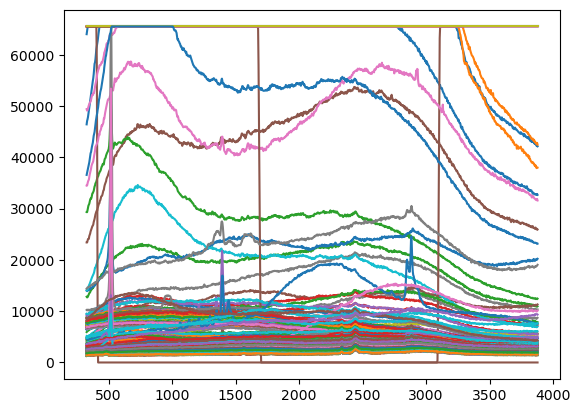

In [51]:
_ = plt.plot(spectra_df.iloc[:,:-4].T)

In [58]:
spectra_df_bg = spectra_df.iloc[:,:-4].loc[:, ~np.isnan(spectra_df.iloc[:1,:-4]).to_numpy().flatten()]
#spectra_df_bg.iloc[np.where(np.isnan(spectra_df_bg.to_numpy()))[0],
#np.where(np.isnan(spectra_df_bg.to_numpy()))[1]] = 0
spectra_df_bg.shape

(553, 1024)

In [60]:
spectra_df_bg#.mean().mean()

,326.122151,329.593769,333.065387,336.537004,340.008622,343.480240,346.951858,350.423476,353.895094,357.366712,...,3846.342668,3849.814286,3853.285904,3856.757521,3860.229139,3863.700757,3867.172375,3870.643993,3874.115611,3877.587229
0,2304.000000,2276.378418,2325.530518,2373.259521,2390.296143,2413.994385,2437.465332,2458.775635,2464.062256,2453.456299,...,2932.426514,2942.021973,2975.305176,3013.954346,2936.445312,2892.301514,2981.001221,2927.811279,2995.498047,2882.000000
1,2059.600098,2056.443359,2061.369629,2071.132324,2069.664062,2017.922974,2061.501953,2084.131592,2083.615723,2083.363037,...,2585.857910,2577.507080,2570.121582,2517.821045,2538.544434,2561.123047,2551.999023,2601.756836,2544.270996,2531.333252
2,1743.333374,1794.762207,1828.411987,1844.969727,1856.222412,1891.664429,1905.254883,1896.748169,1897.227417,1909.476196,...,2113.345215,2104.744141,2161.189941,2085.769531,2108.079590,2041.756470,2075.461182,2080.381592,2072.018311,2046.666626
3,2304.399902,2323.971924,2327.626465,2344.936768,2375.666260,2375.982178,2384.952148,2409.253906,2420.137207,2404.281494,...,2789.241699,2839.861328,2784.926514,2749.770752,2816.884766,2814.019531,2777.423584,2766.565918,2770.747803,2761.500000
4,3180.800049,3152.073486,3164.758789,3184.590088,3197.000244,3214.510742,3271.078613,3292.951904,3318.340088,3362.363281,...,4637.030273,4602.260742,4632.853027,4573.444824,4621.016113,4529.645996,4589.382812,4613.145020,4590.461426,4669.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1763.666626,1767.875610,1806.881348,1834.000000,1843.650269,1889.730103,1868.211914,1873.739868,1886.172363,1889.294434,...,1926.293823,1953.746704,1943.083008,1951.496704,1913.042969,1925.578491,1897.287842,1904.529541,1928.244751,1954.333374
96,1463.000000,1489.043213,1530.190308,1556.794434,1558.425415,1549.314697,1549.695190,1576.656860,1600.327026,1602.089233,...,1725.065918,1706.474121,1707.677856,1672.435547,1688.183350,1698.883423,1688.512085,1688.883423,1664.963257,1663.000000
97,1747.599976,1766.067017,1781.839844,1797.823242,1817.273560,1844.842529,1885.889526,1877.149170,1867.774414,1888.208618,...,2080.161865,2139.676025,2088.219238,2045.206665,2064.376953,2052.928223,2074.326660,2067.727539,2086.605957,2087.333252
98,1428.000000,1429.578369,1459.372681,1470.612183,1459.130859,1482.039185,1489.798828,1498.225830,1513.418457,1530.628418,...,1587.678955,1558.691650,1559.207275,1555.447021,1561.334473,1552.813843,1571.627686,1550.808105,1523.053955,1557.500000


In [325]:
#spectra_data_diff = np.diff(spectra_df_bg)
#spectra_df_bg = (spectra_df_bg - spectra_df_bg.mean(1)[:,None]) / spectra_df_bg.std(1)[:,None]

In [61]:
kmeans = KMeans(n_clusters=40, random_state=1).fit(spectra_df_bg)
pred = kmeans.predict(spectra_df_bg)

In [72]:
#import pickle 
#filename = 'bg_classifier_1.sav'
#pickle.dump(kmeans, open(filename, 'wb'))

In [65]:
pd.DataFrame({'cluster':pred, 'count':1}).groupby('cluster').sum().query('count >= 10')

,count
cluster,
0,110
2,53
7,28
16,12
19,100
27,17
30,50
31,101
37,13


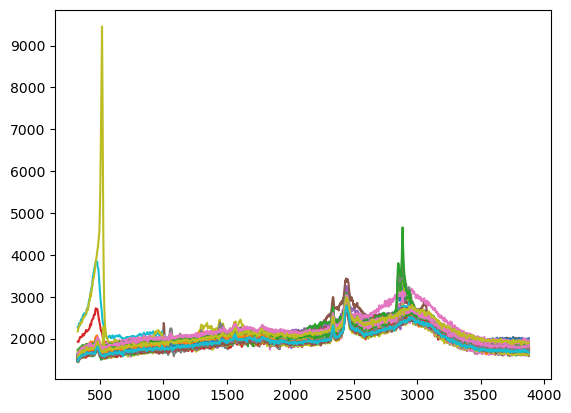

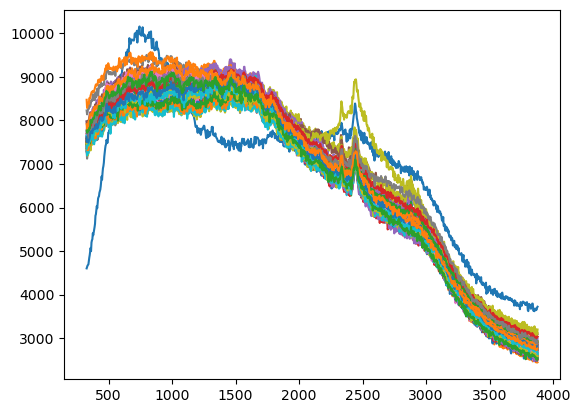

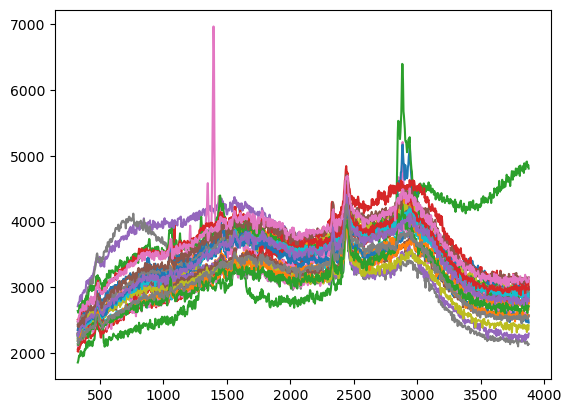

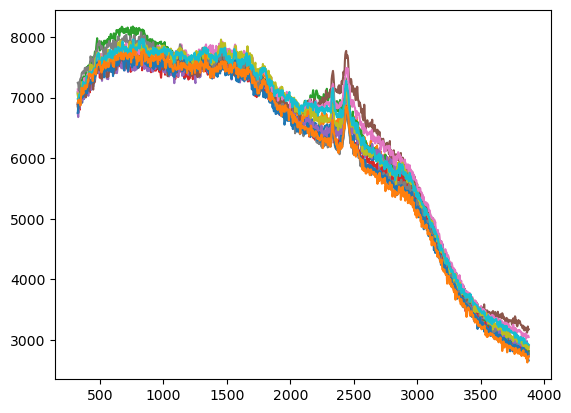

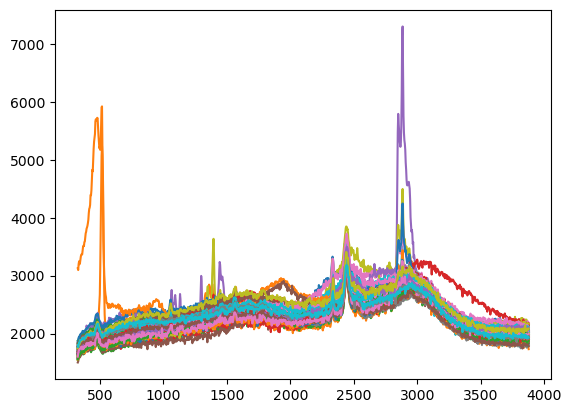

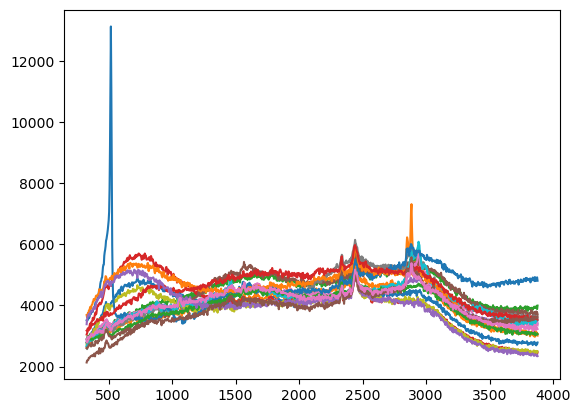

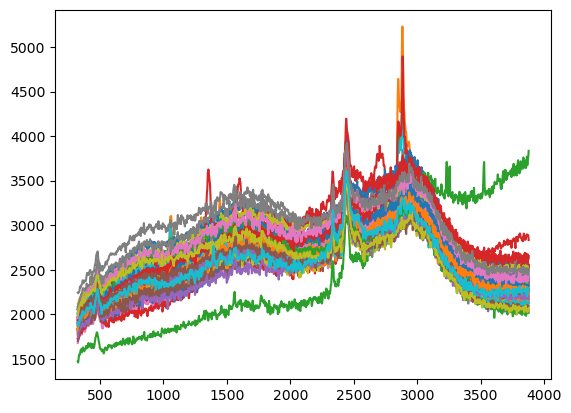

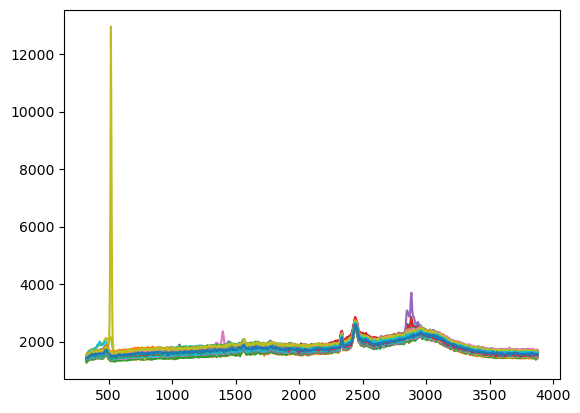

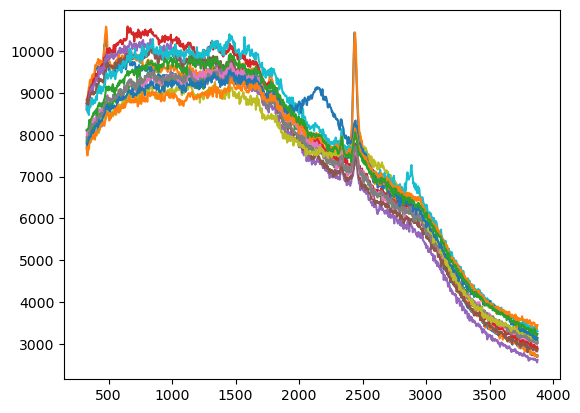

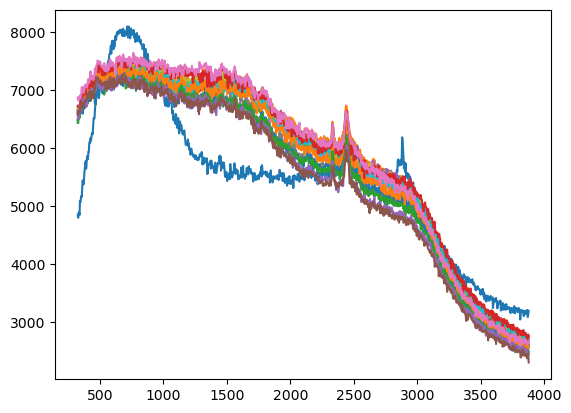

In [66]:
for i in pd.DataFrame({'cluster':pred, 'count':1}).groupby('cluster').sum().query('count >= 10').index:
    _ = plt.plot(spectra_df_bg.loc[(pred == i),:].T)
    plt.show()

In [44]:
spectra_bg_1 = spectra_df.loc[pred == 0, 'id']

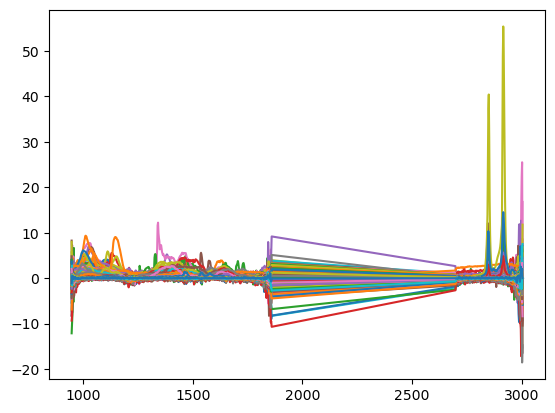

In [45]:
_ = plt.plot(spectra_df_bg.loc[(pred == 0),:].T)

In [75]:
kmeans2 = KMeans(n_clusters=10, random_state=0).fit(spectra_df_bg.loc[(pred == 0),:])

filename = 'bg_classifier_2.sav'
pickle.dump(kmeans2, open(filename, 'wb'))

In [74]:
pred_2 = kmeans2.predict(spectra_df_bg.loc[(pred == 0),:])
pd.DataFrame({'cluster':pred_2, 'count':1}).groupby('cluster').sum()

,count
cluster,
0,283
1,187
2,21
3,23
4,1
5,20
6,419
7,56
8,5


0 283


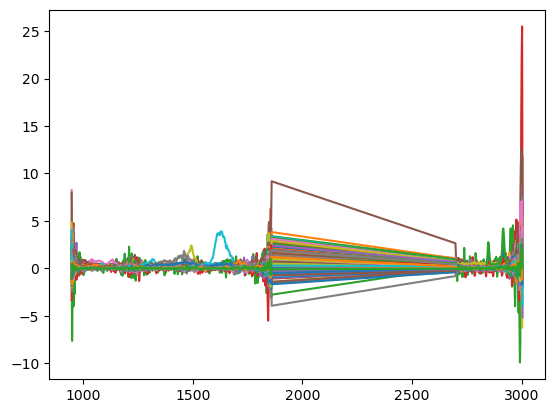

1 187


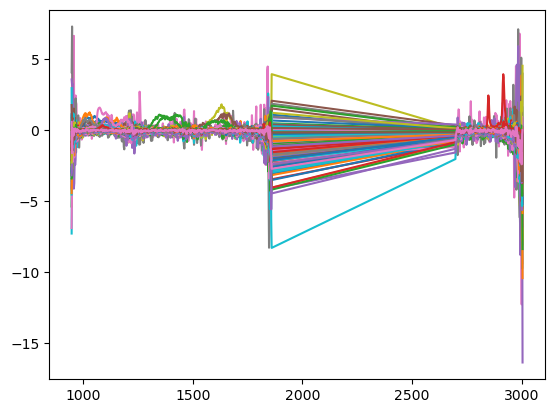

2 21


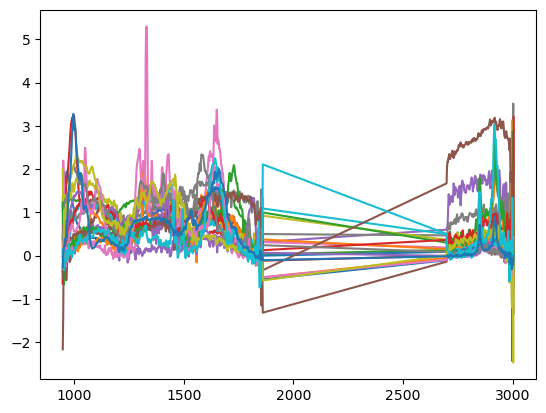

3 23


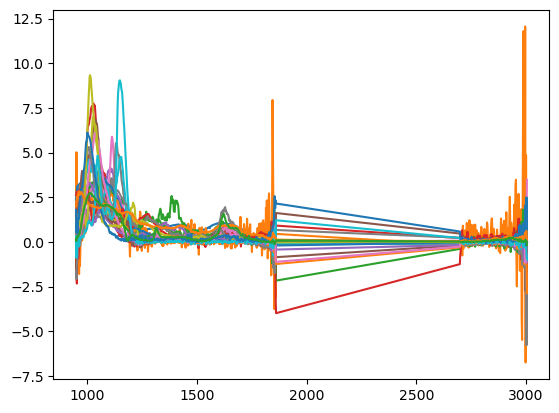

4 1


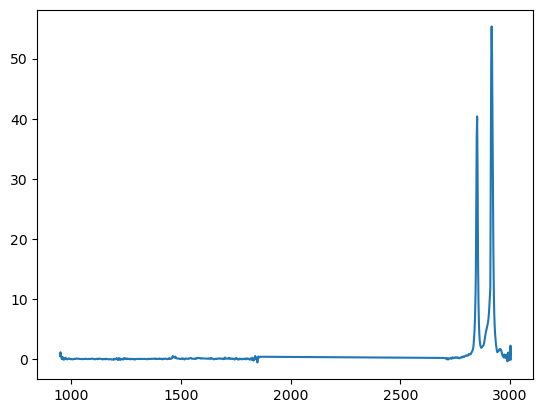

5 20


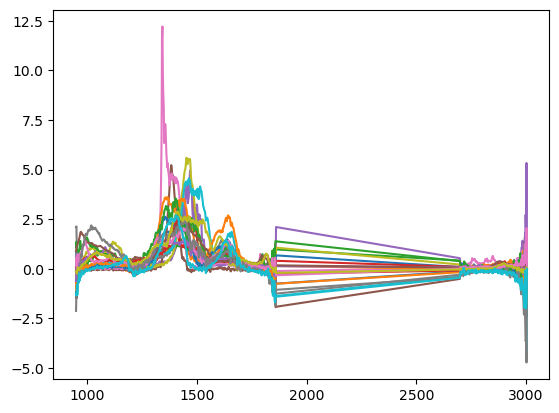

6 419


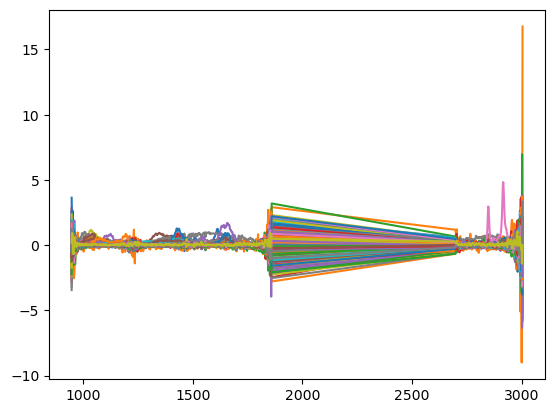

7 56


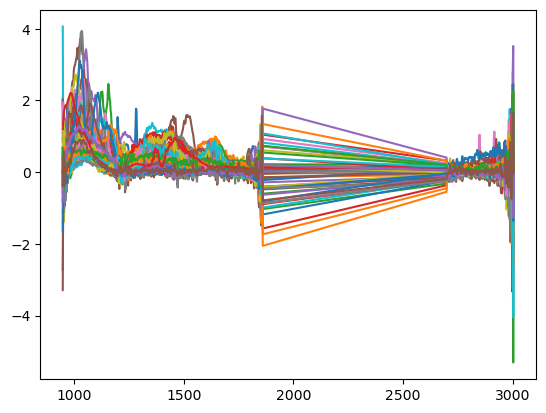

8 5


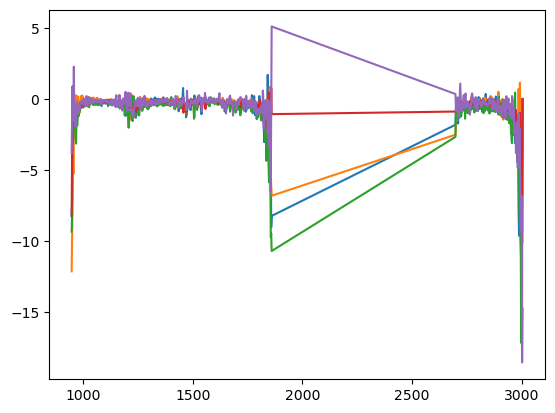

9 6


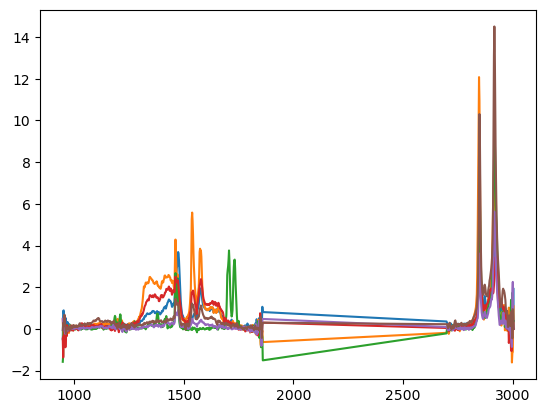

In [49]:
#cluster = 9
for cluster in pd.DataFrame({'cluster':pred_2, 'count':1}).groupby('cluster').sum().index:
    print(cluster, spectra_df_bg.iloc[(pred == 0),:].iloc[(pred_2 == cluster),:].shape[0])
    _ = plt.plot(spectra_df_bg.loc[(pred == 0),:].loc[(pred_2 == cluster),:].T)
    plt.show()

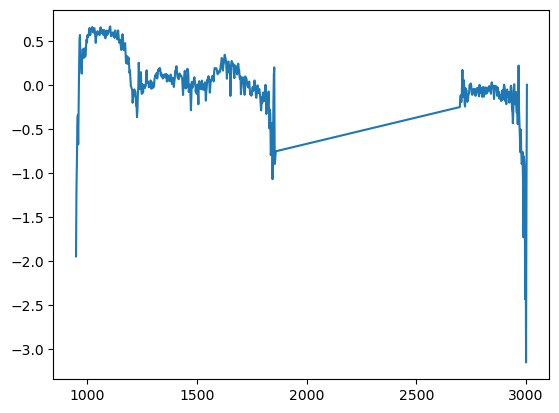

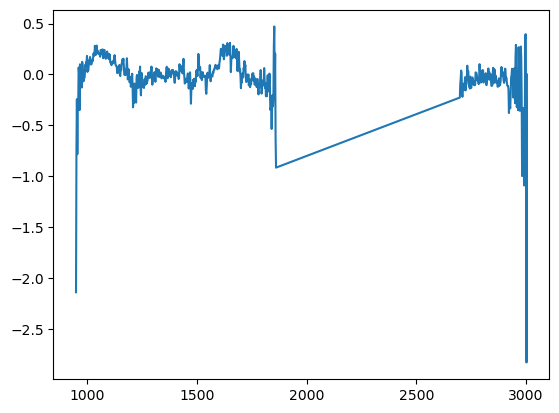

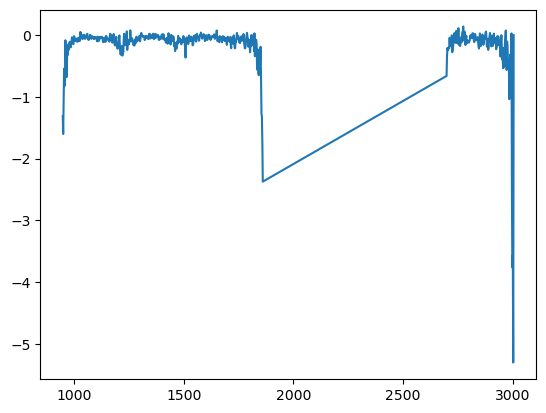

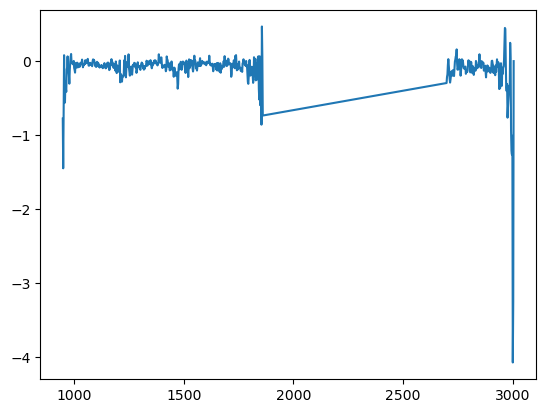

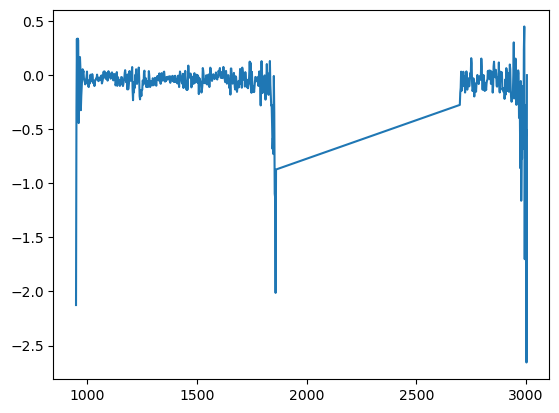

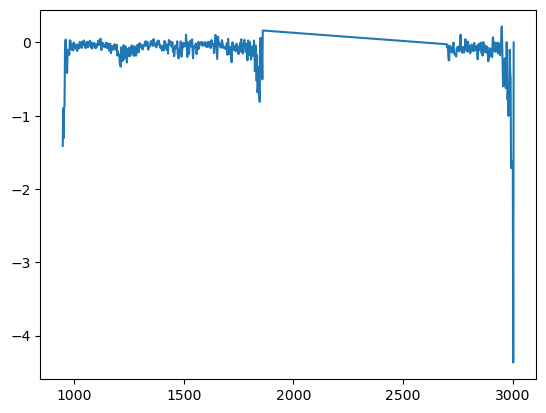

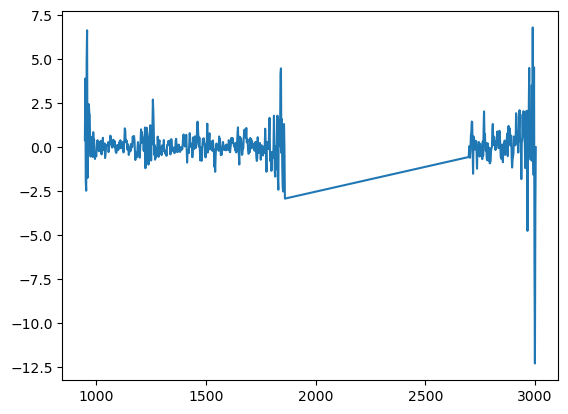

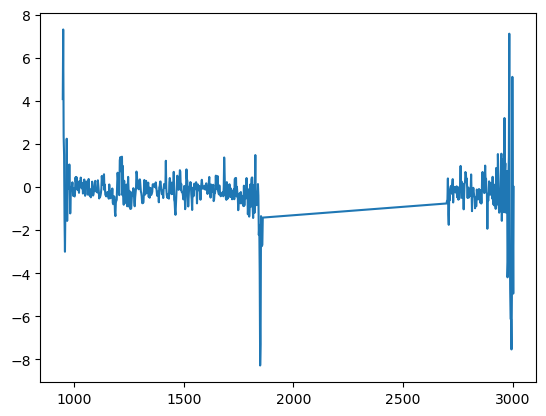

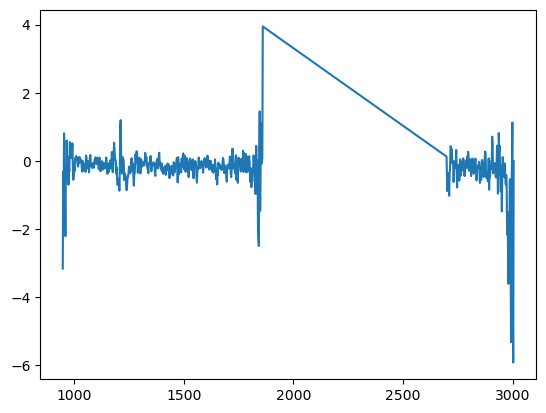

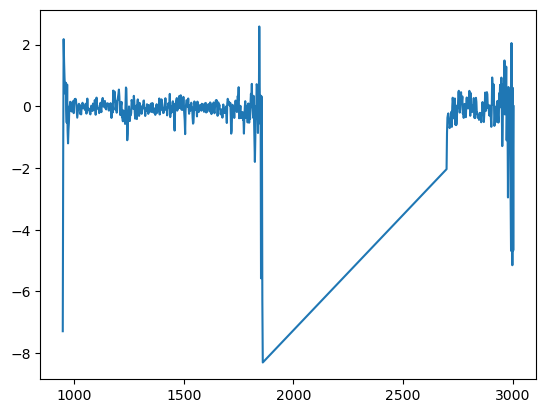

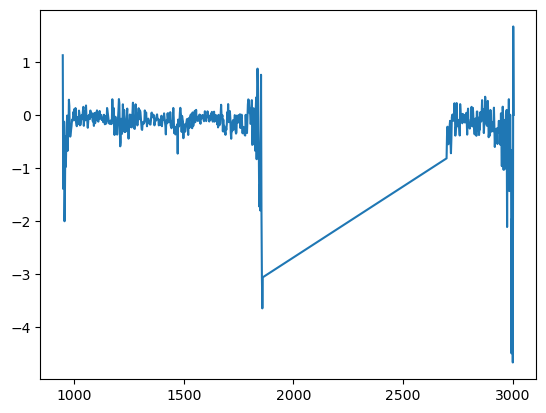

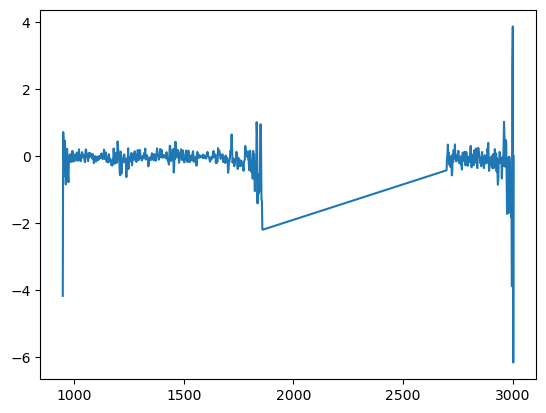

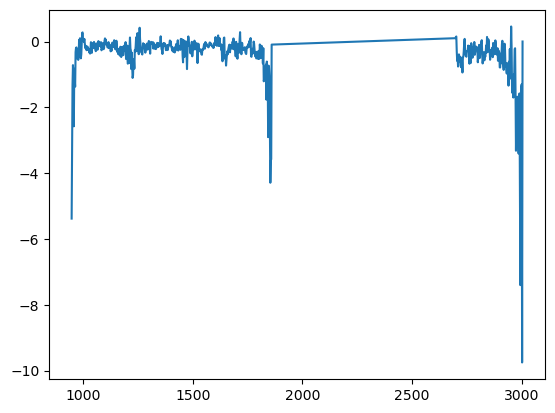

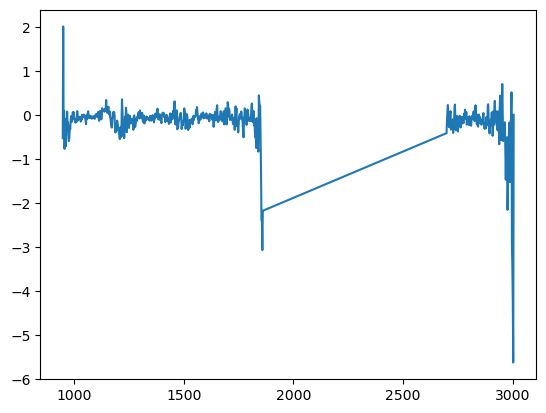

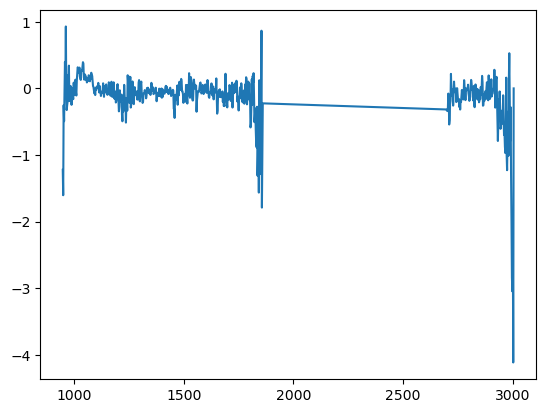

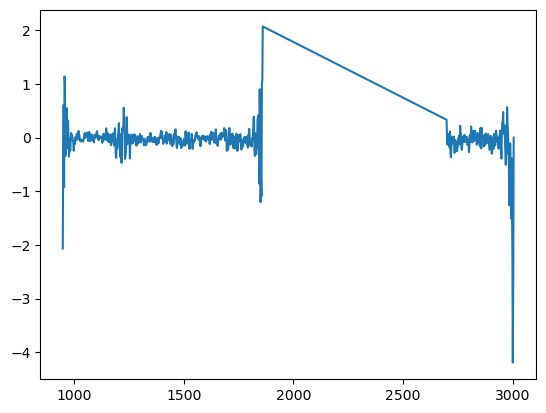

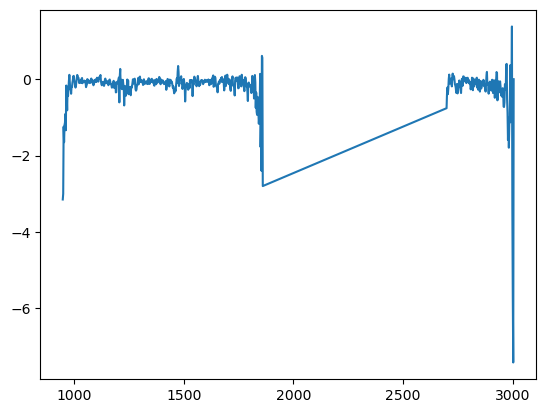

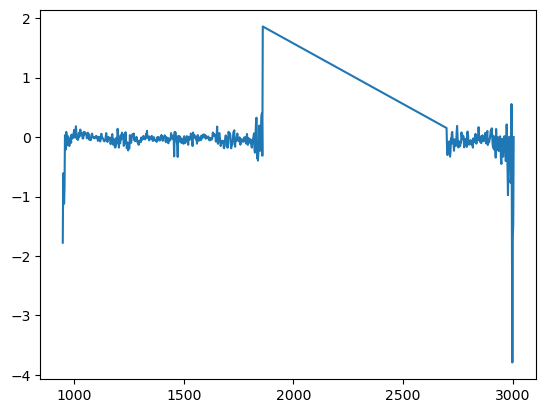

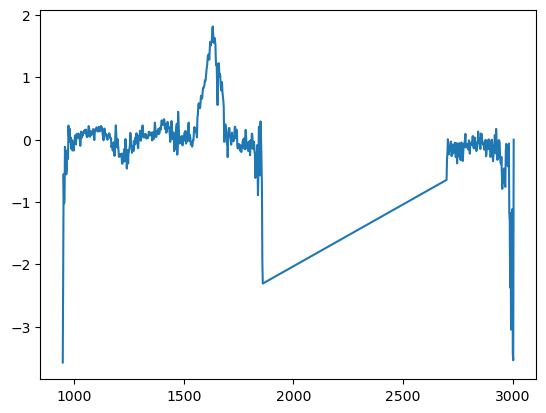

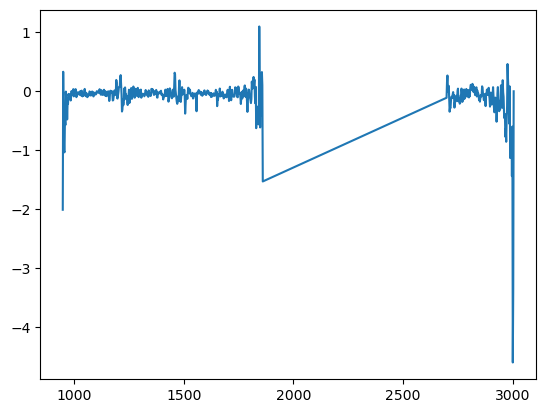

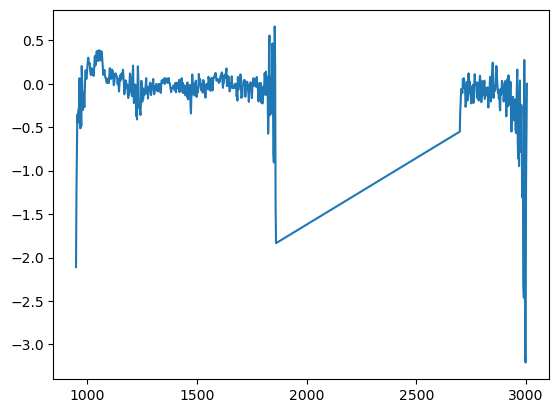

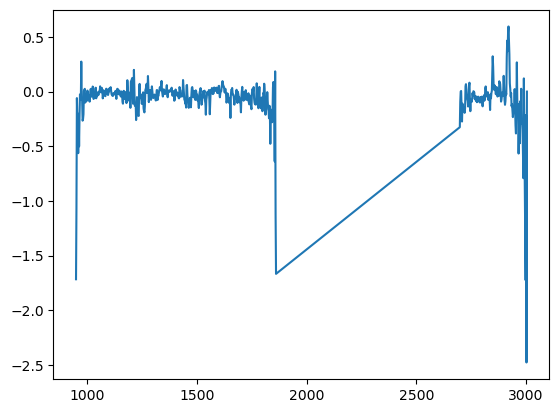

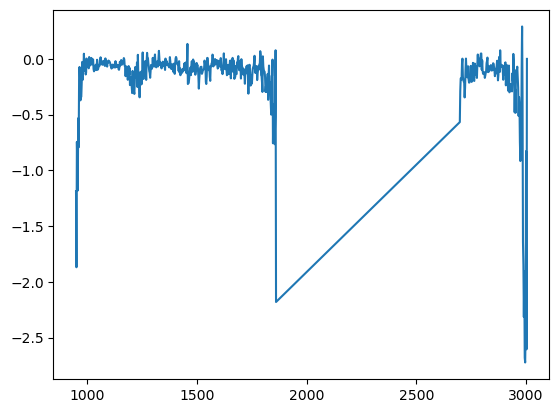

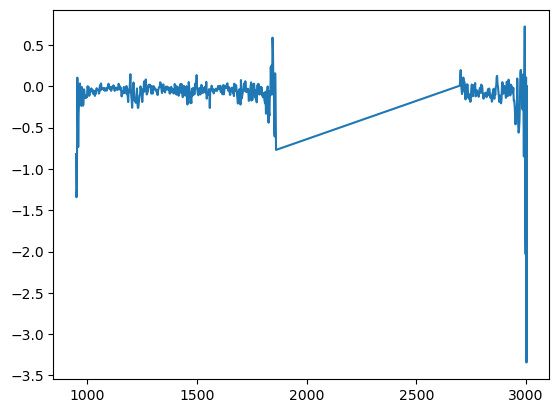

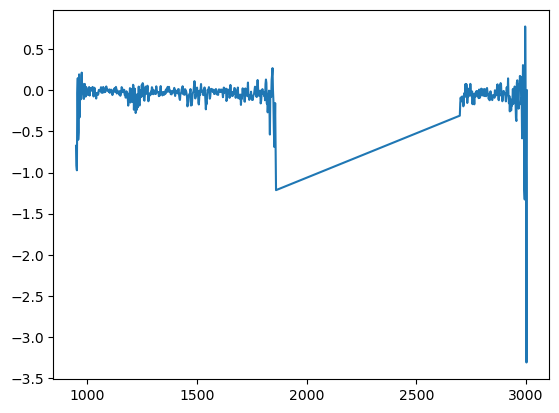

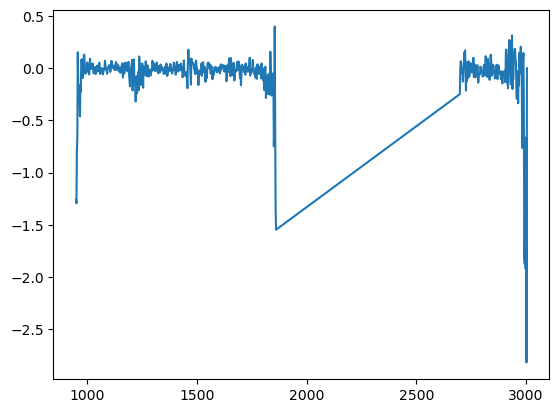

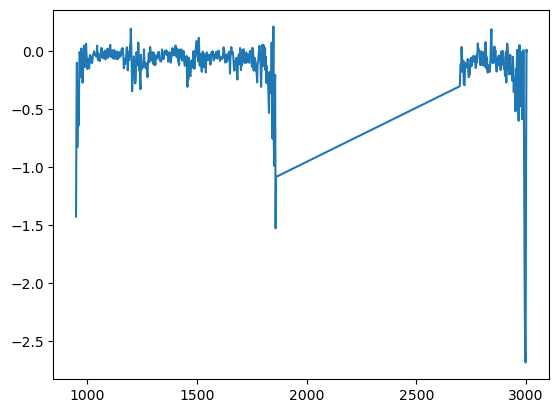

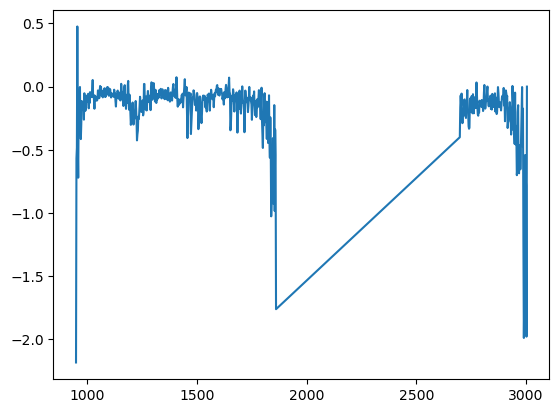

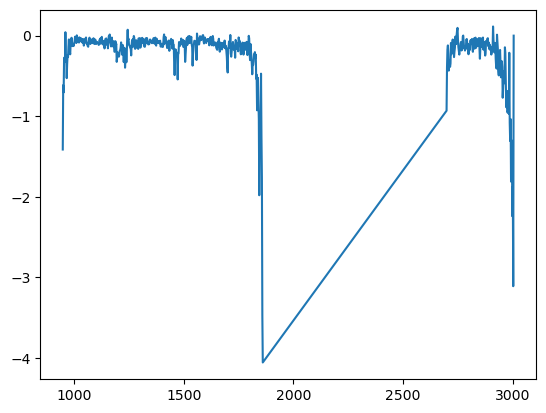

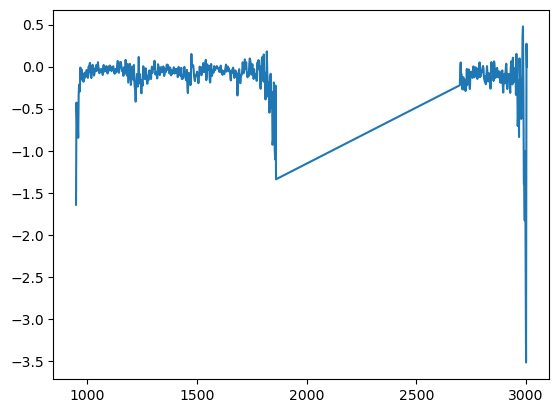

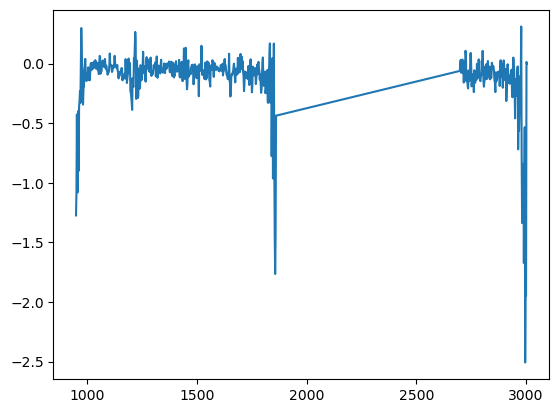

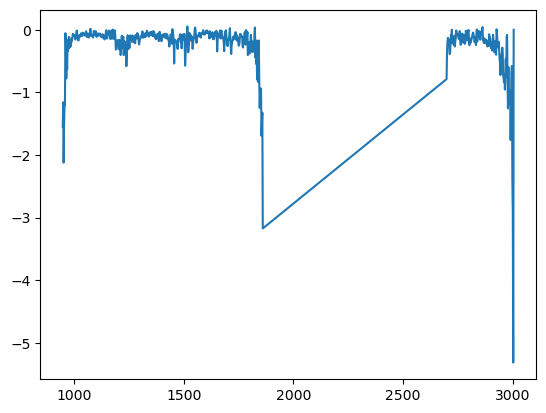

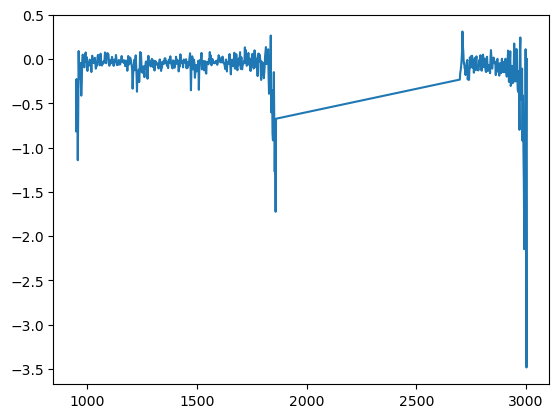

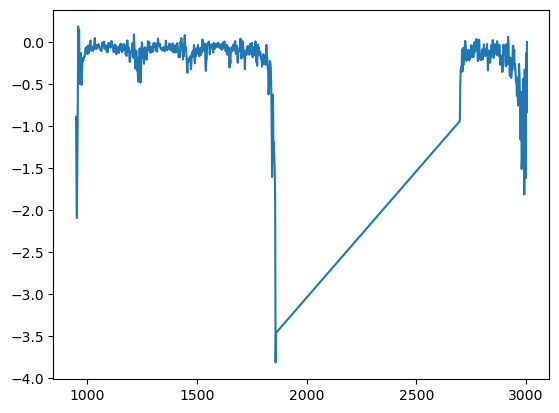

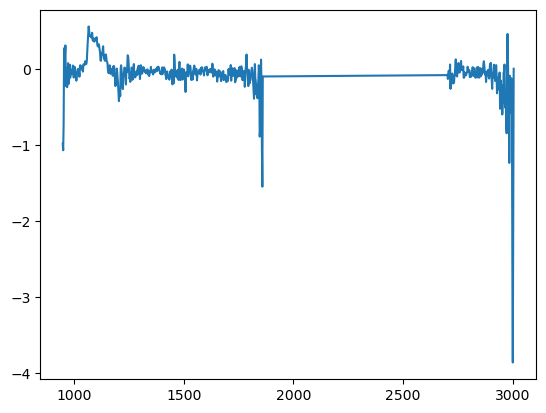

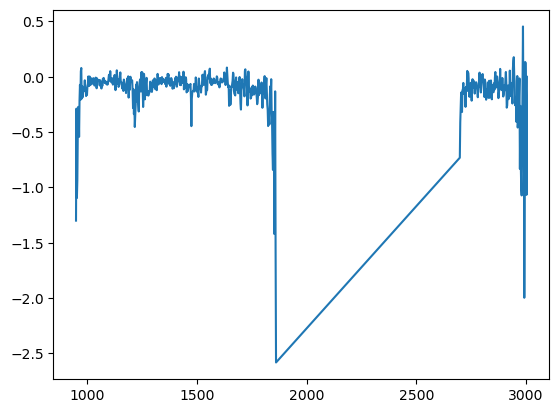

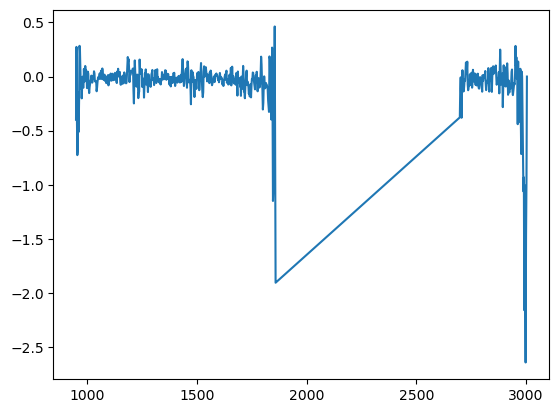

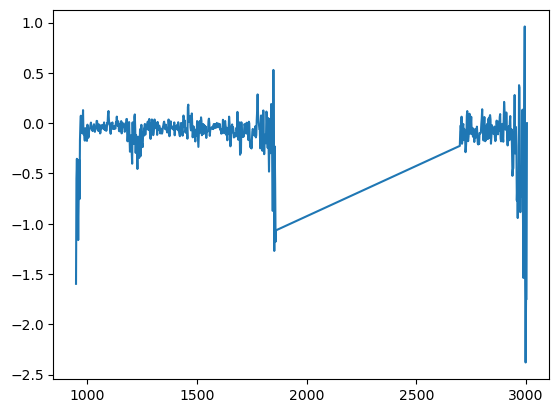

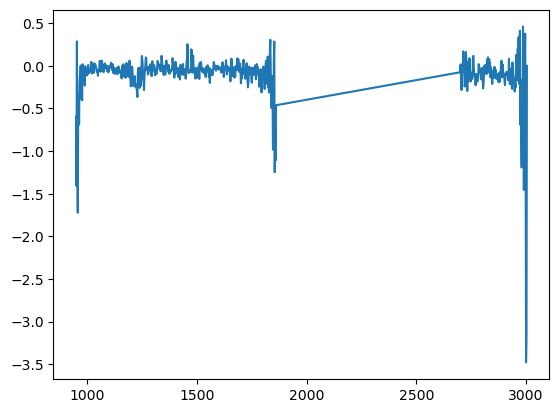

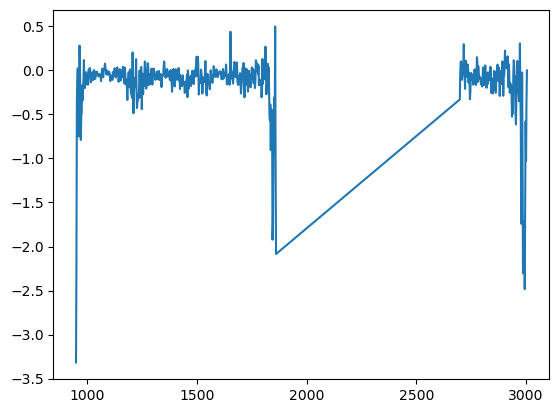

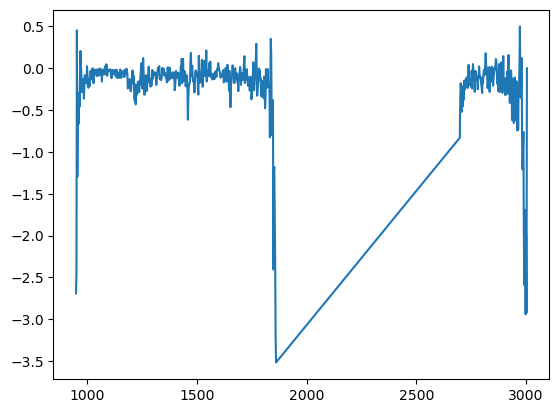

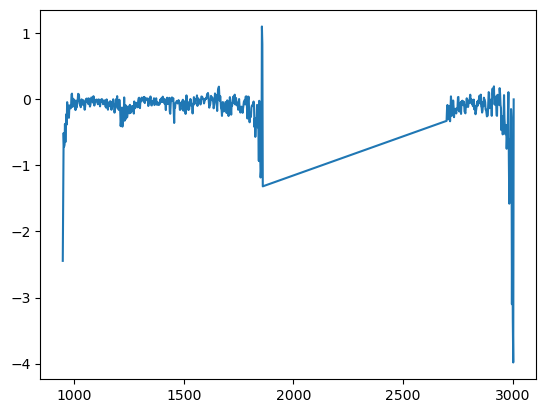

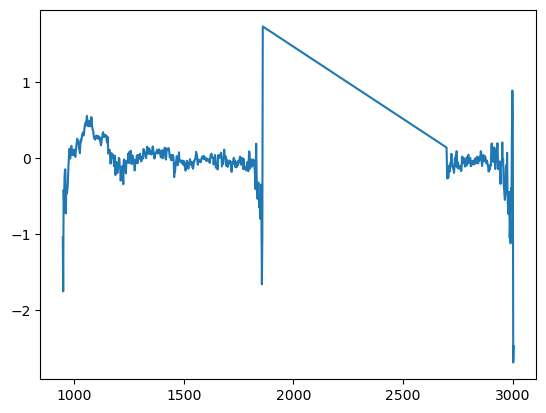

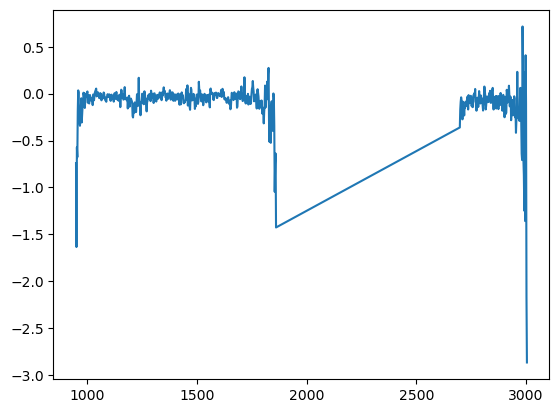

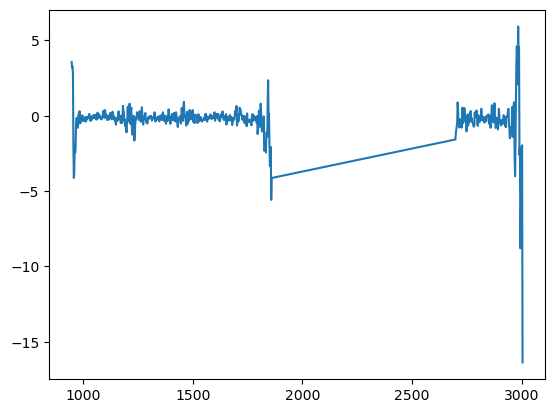

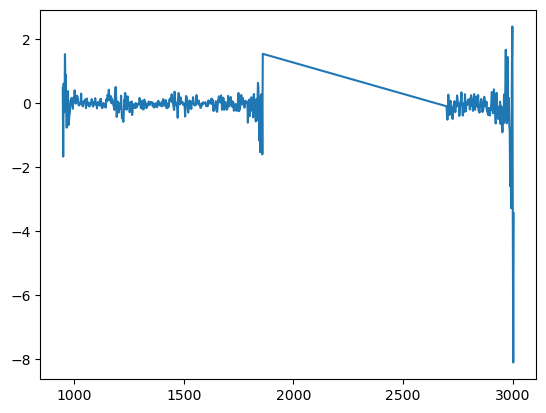

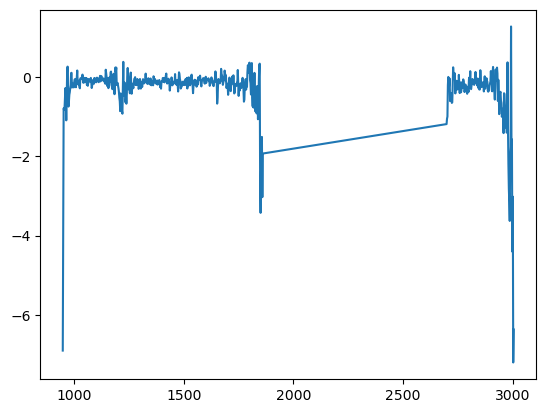

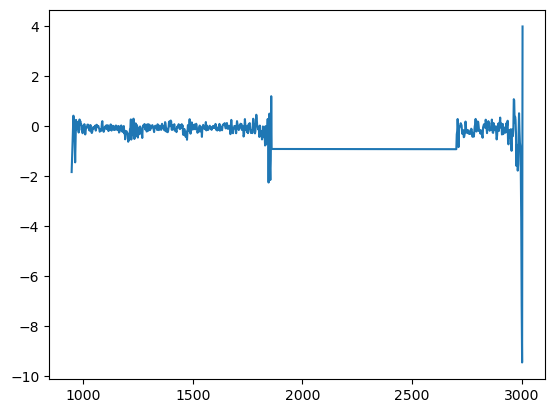

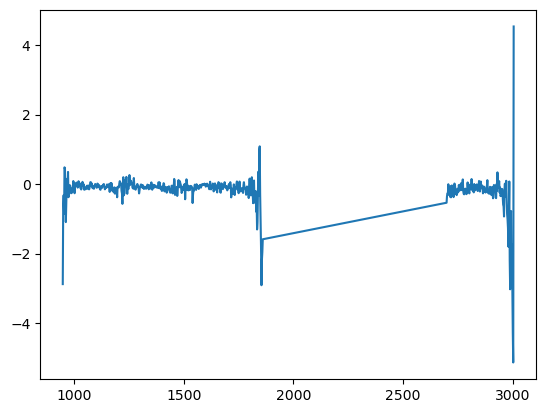

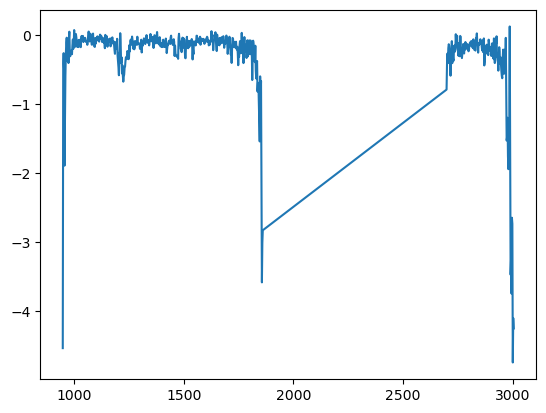

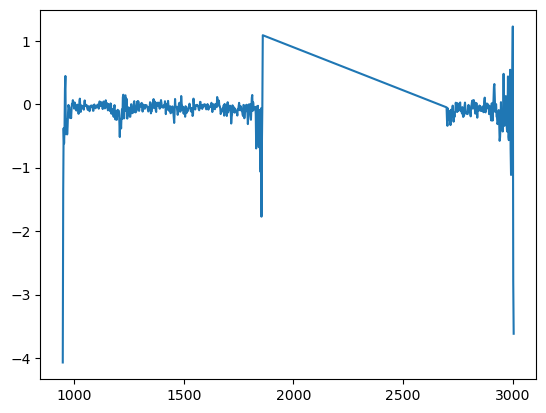

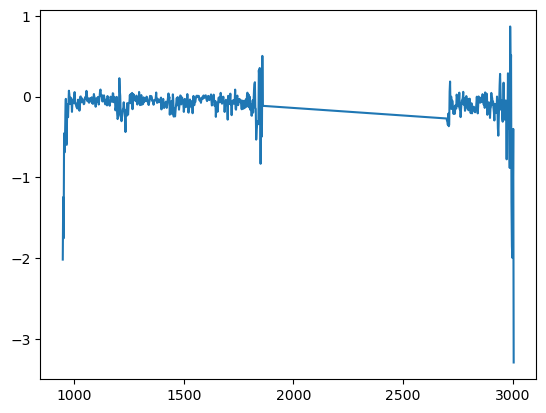

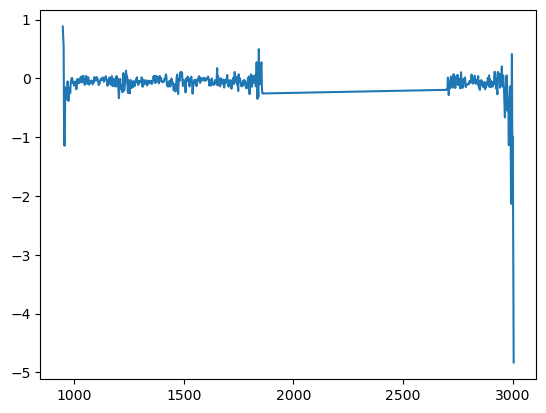

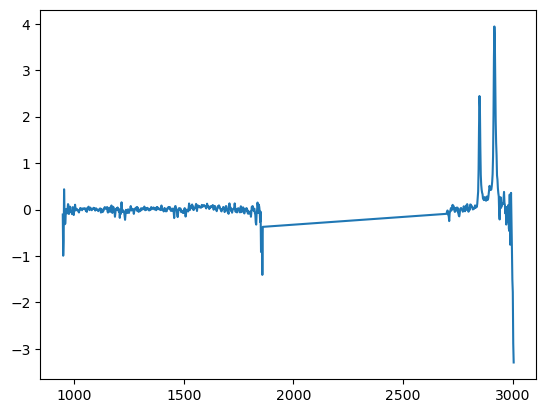

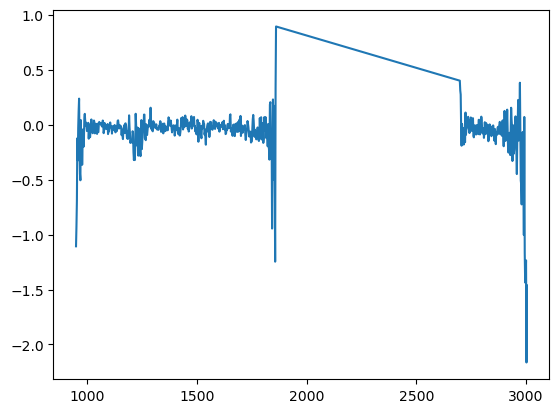

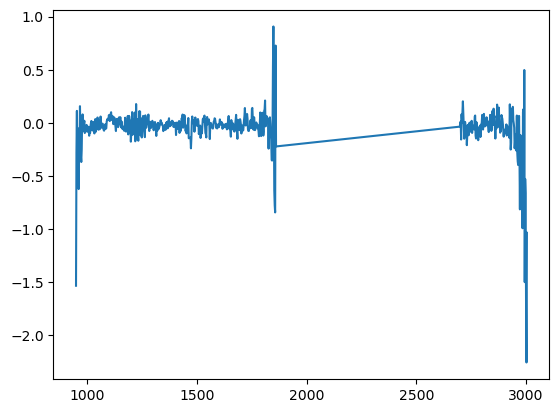

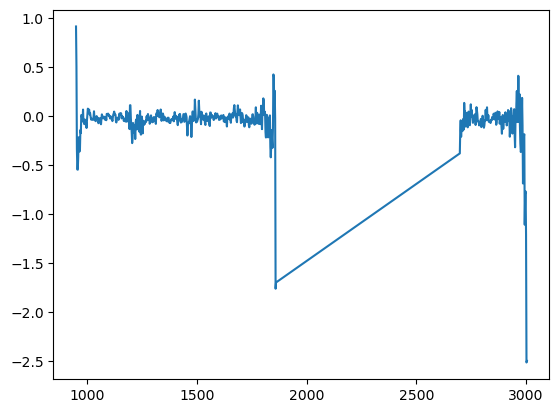

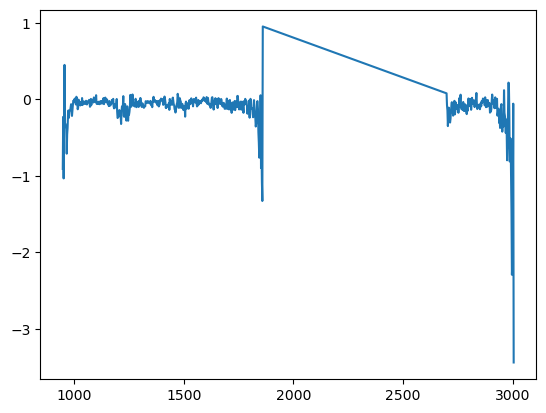

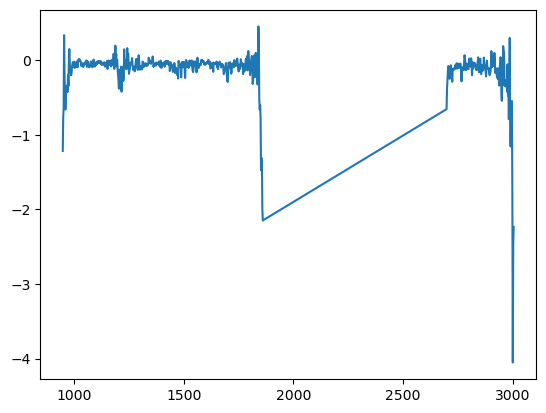

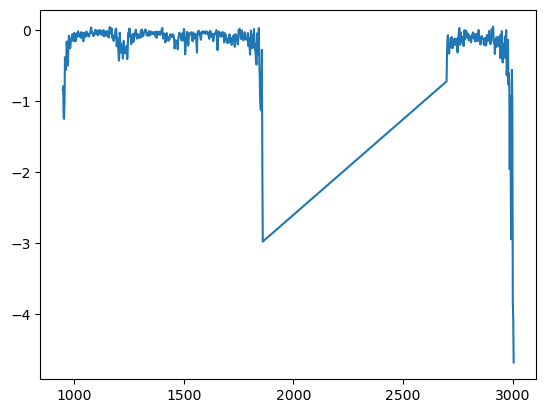

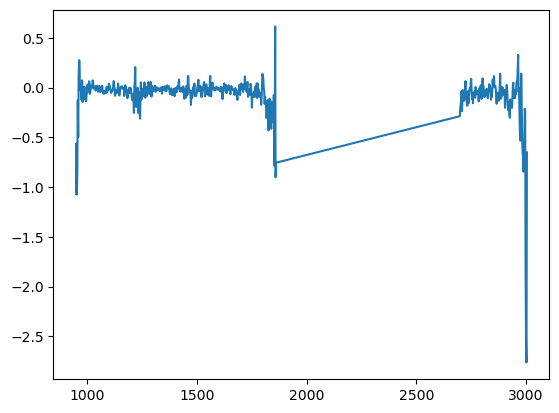

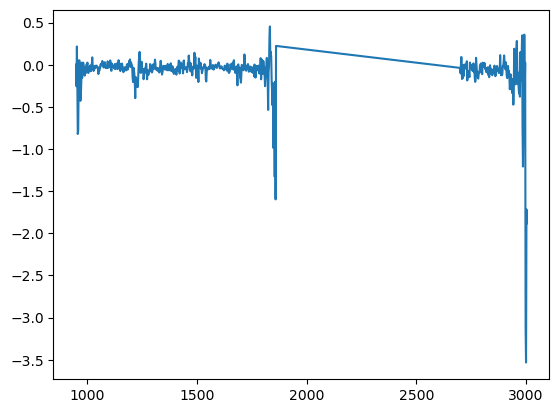

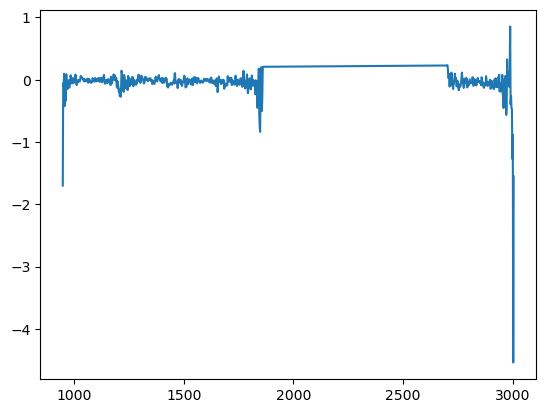

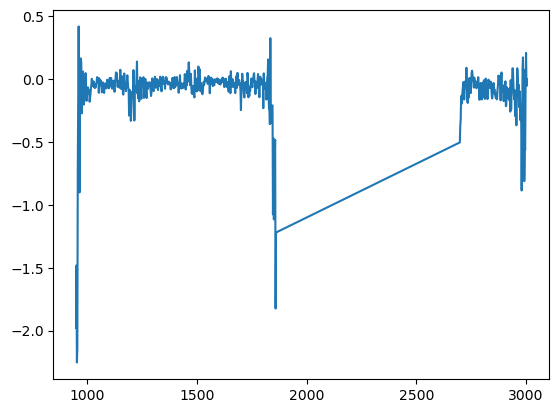

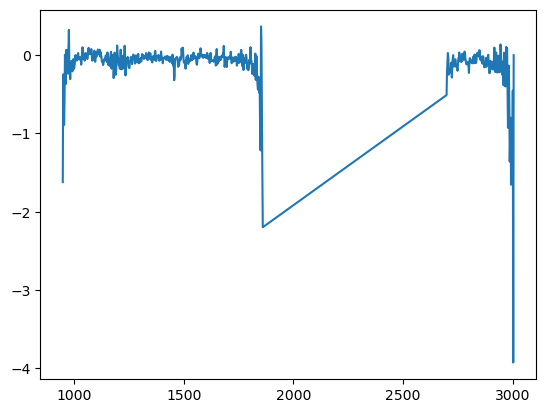

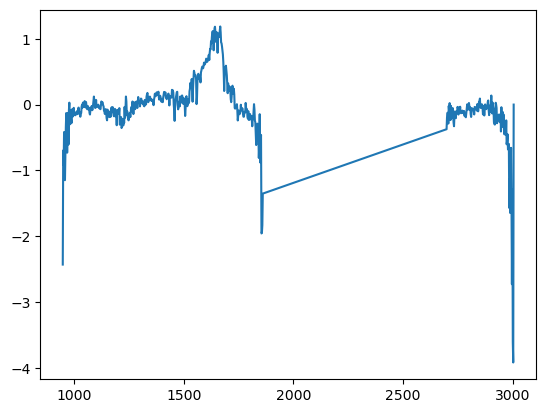

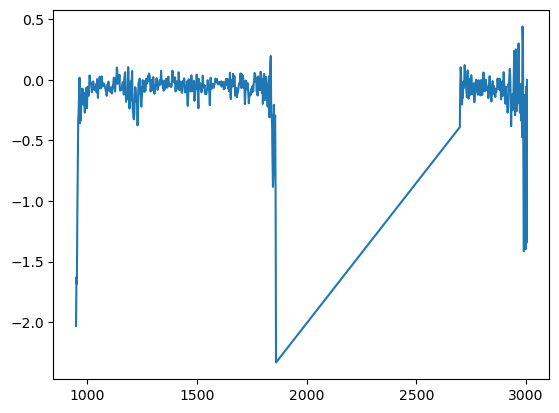

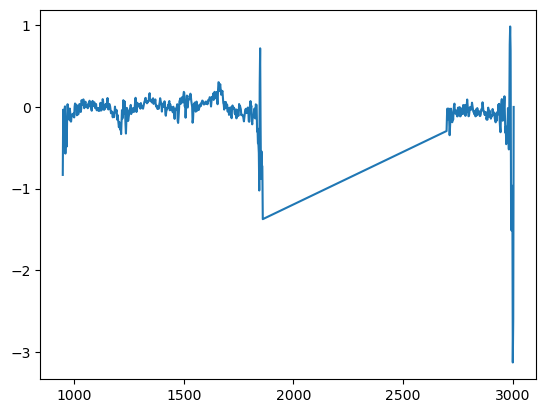

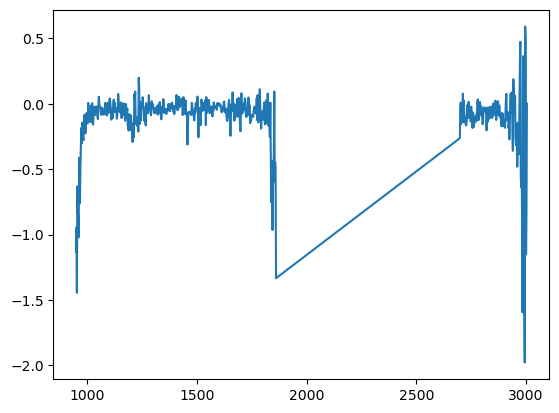

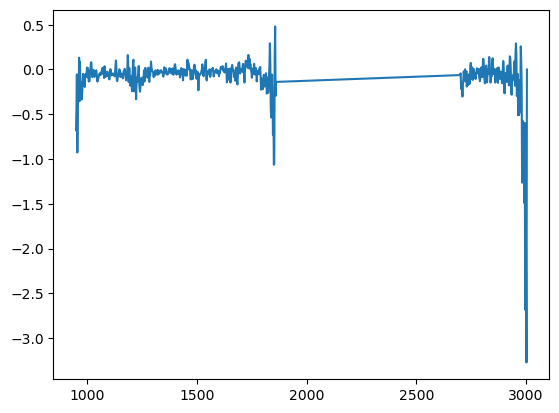

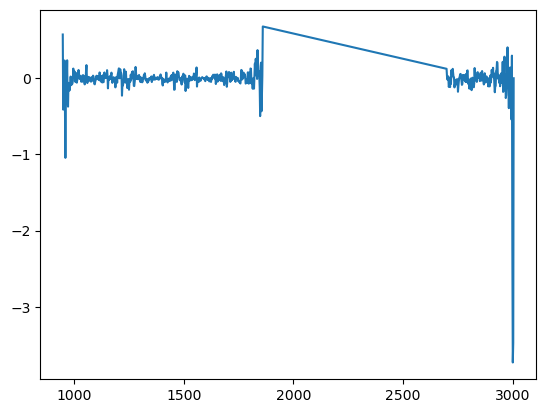

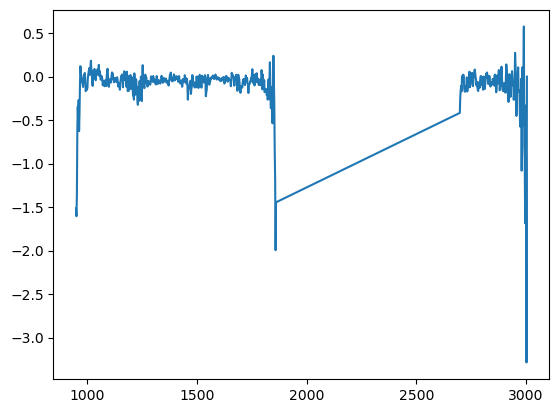

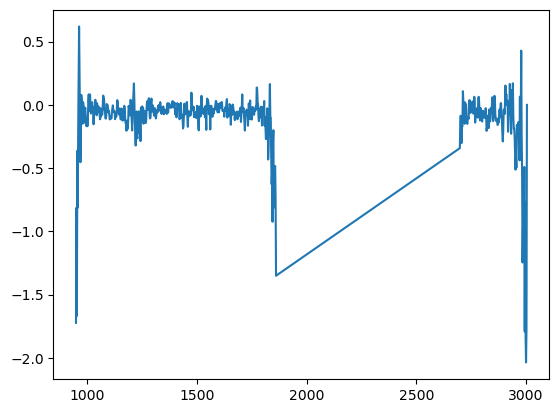

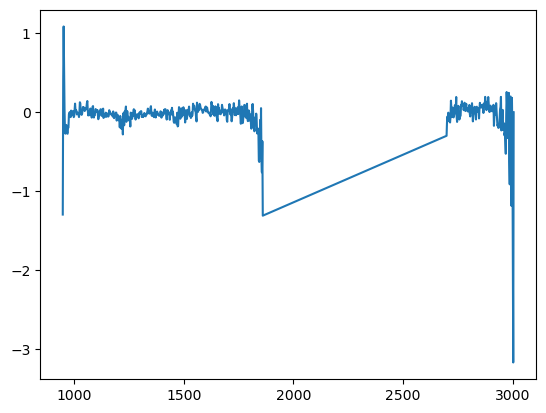

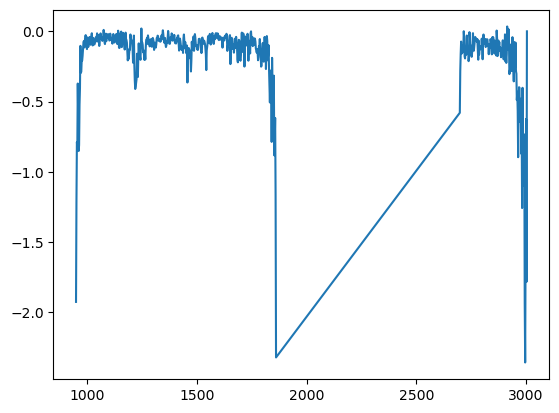

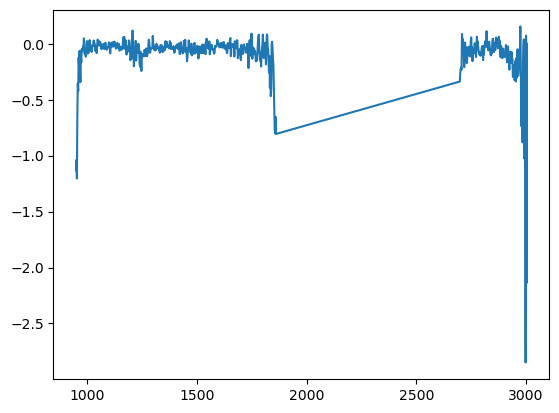

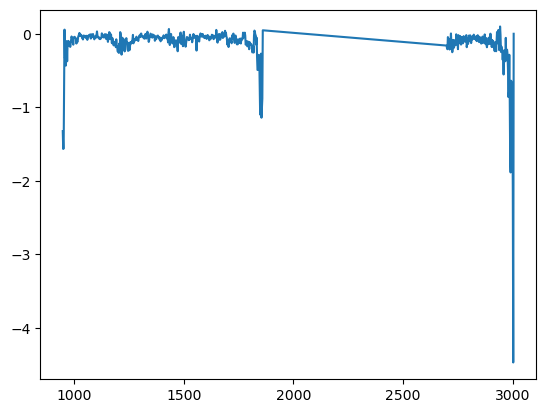

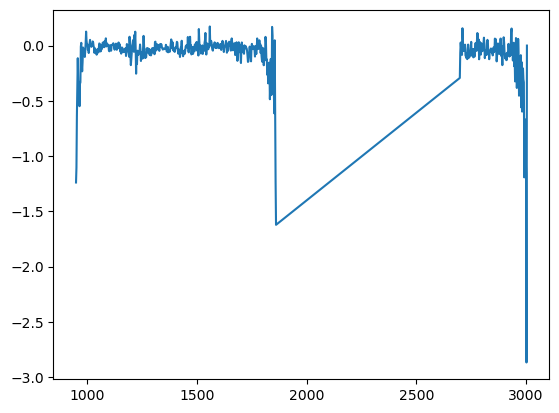

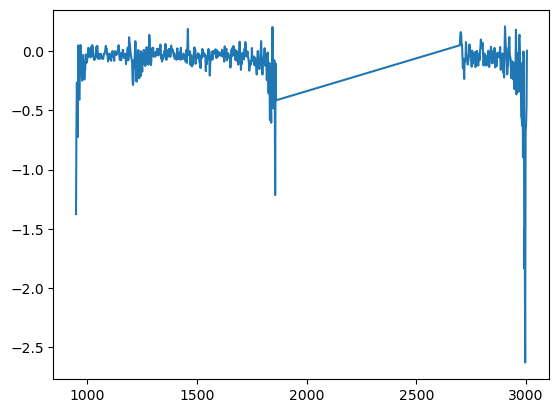

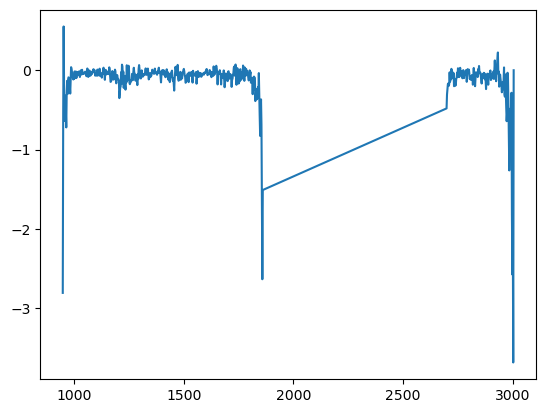

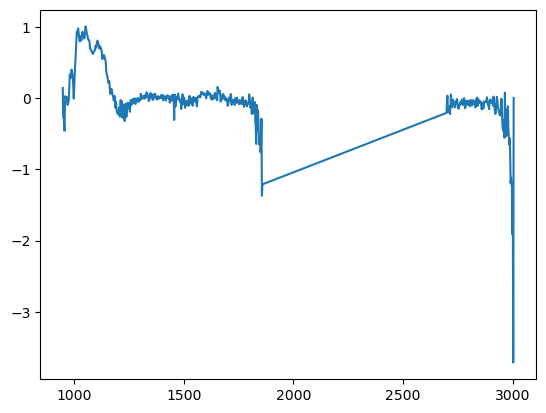

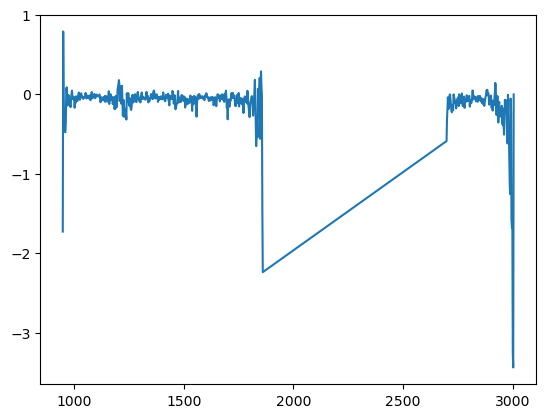

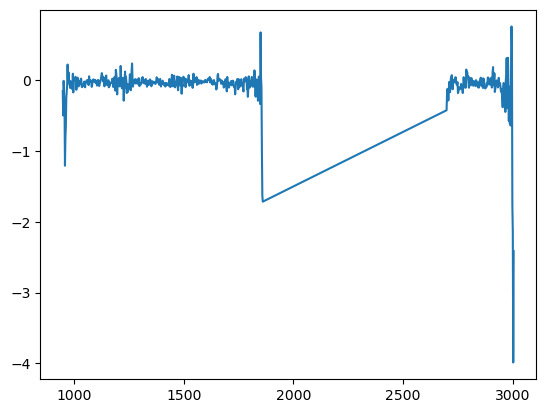

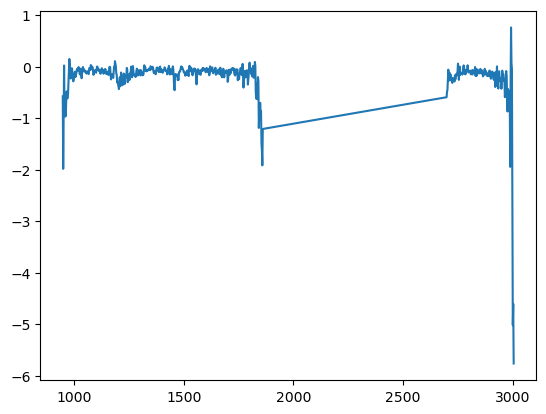

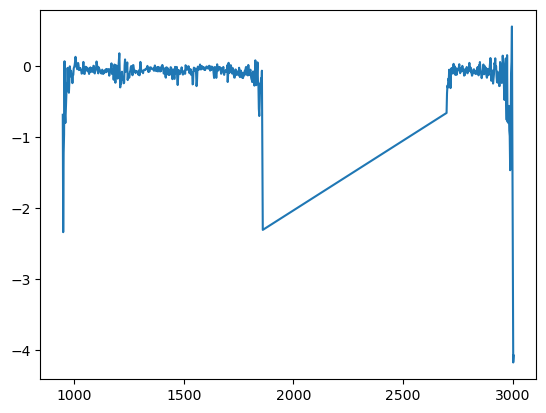

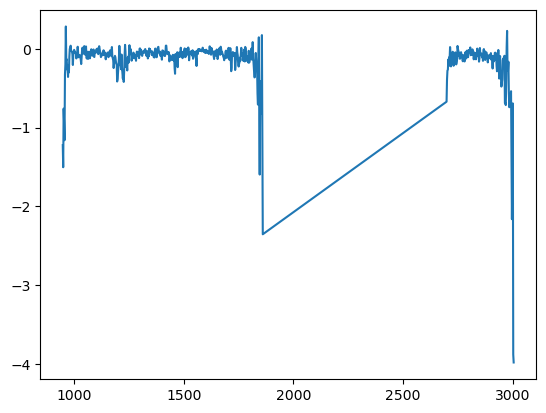

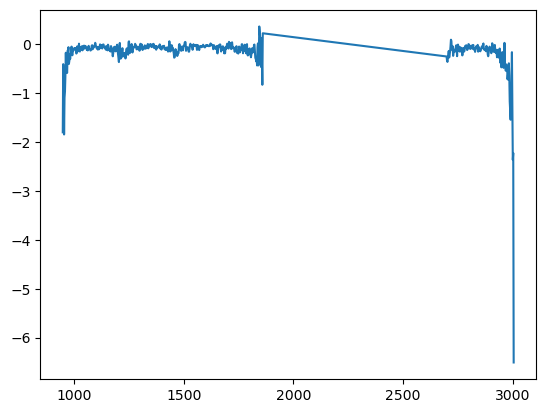

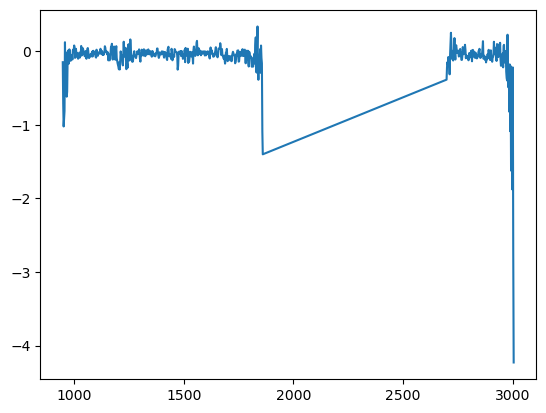

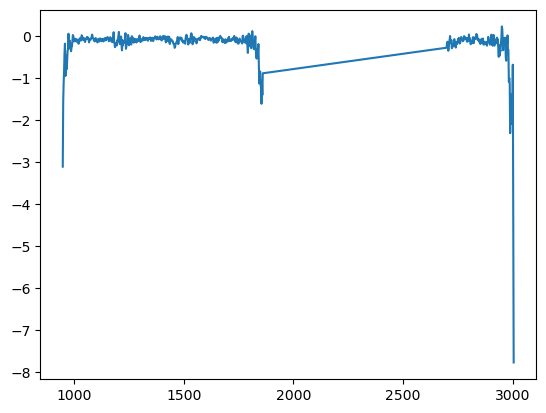

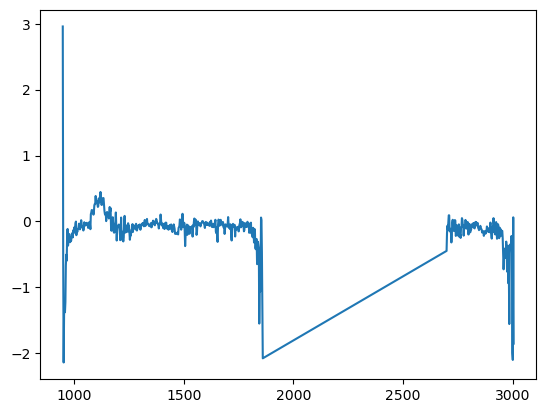

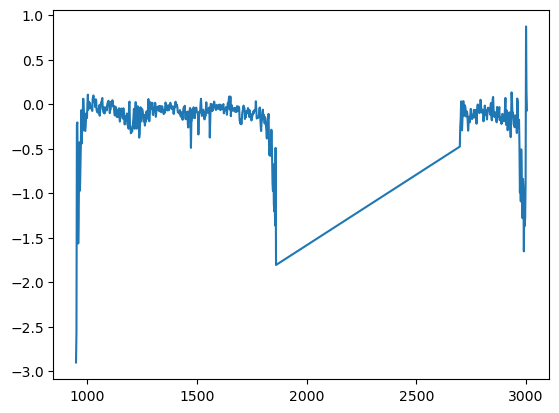

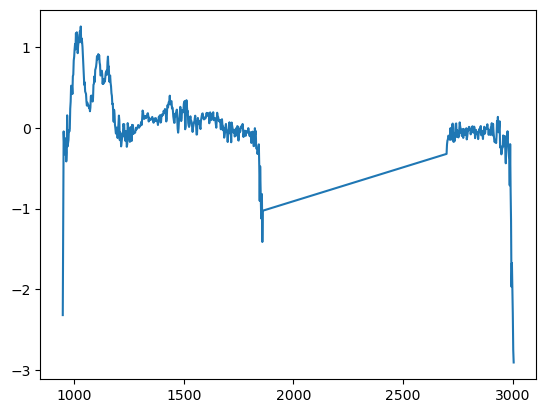

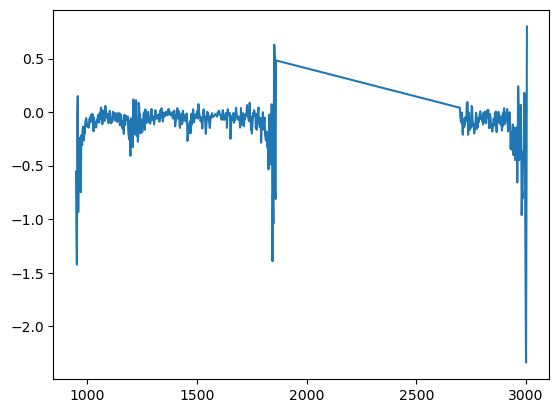

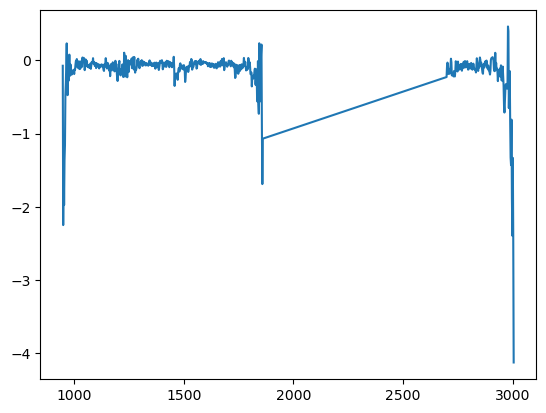

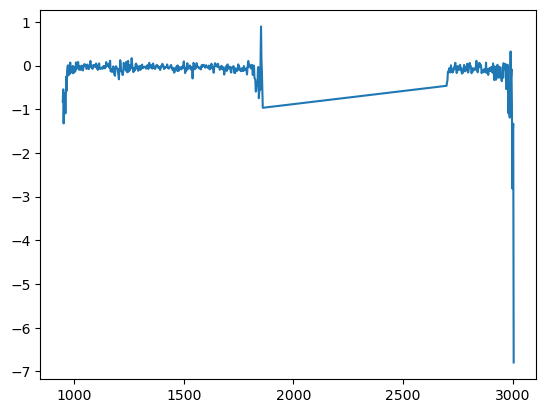

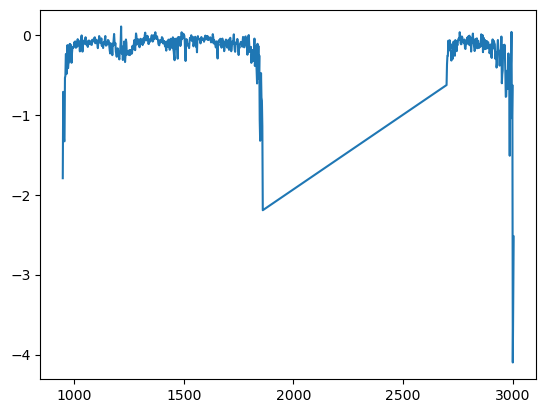

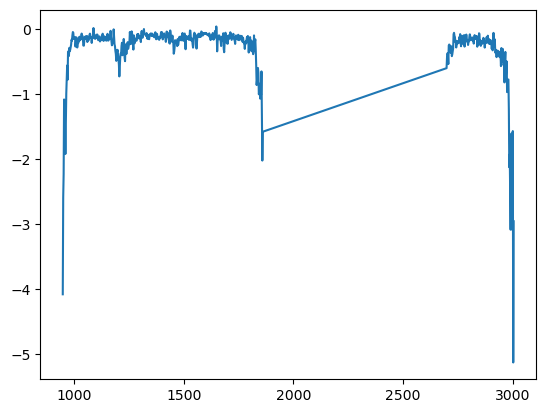

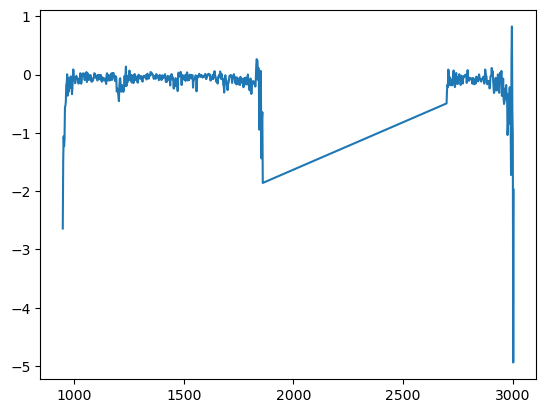

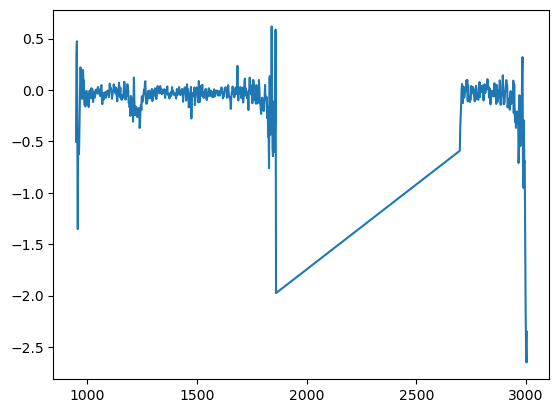

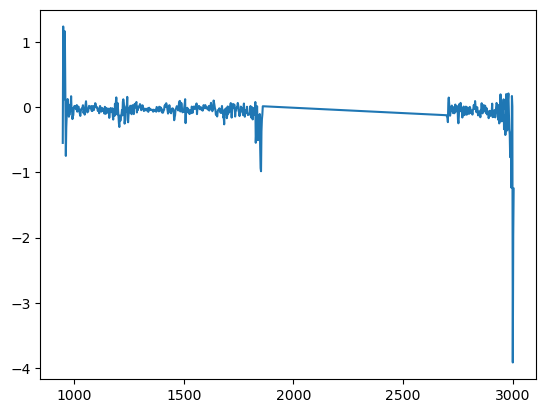

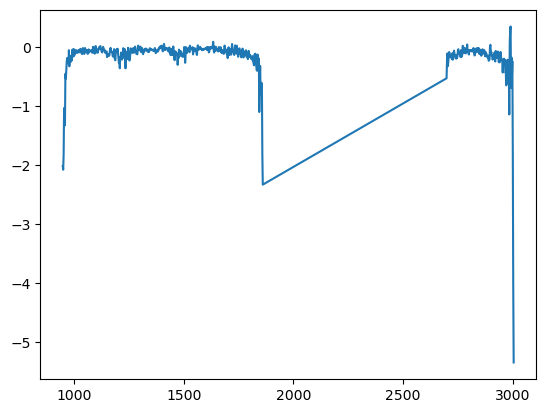

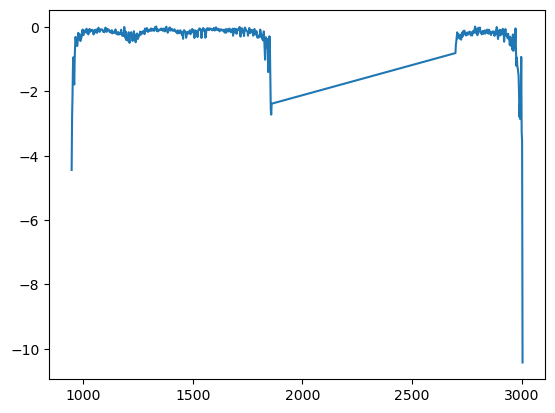

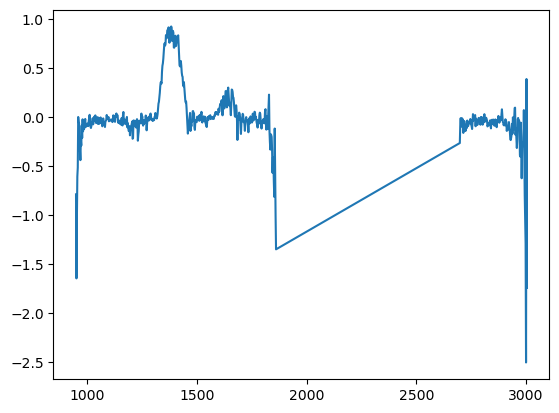

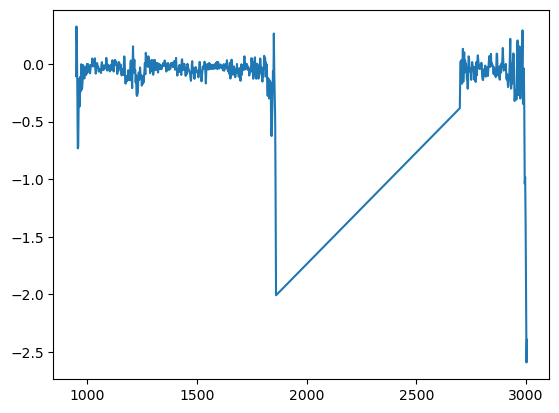

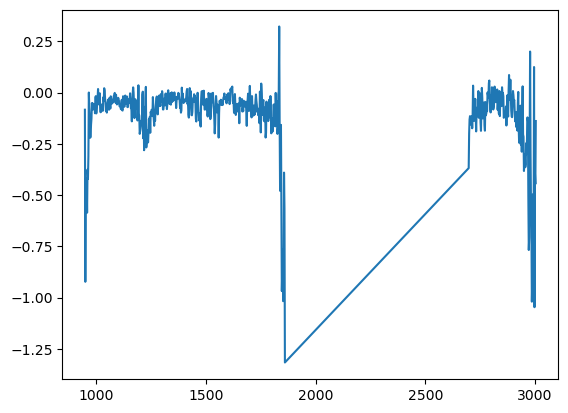

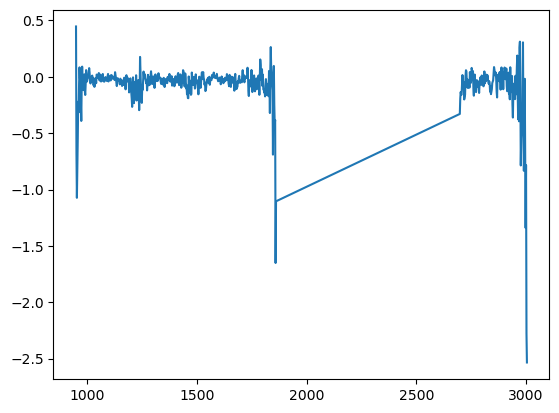

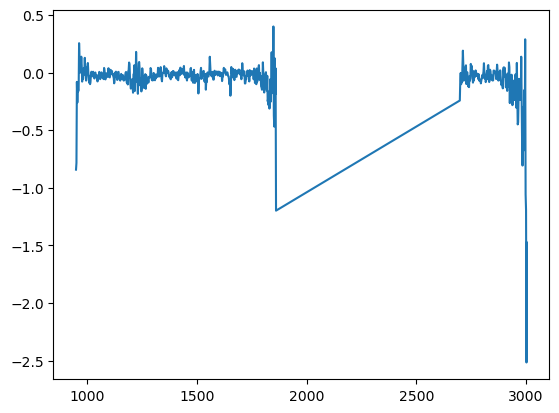

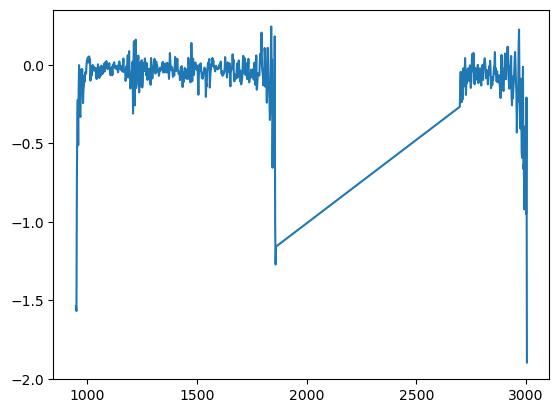

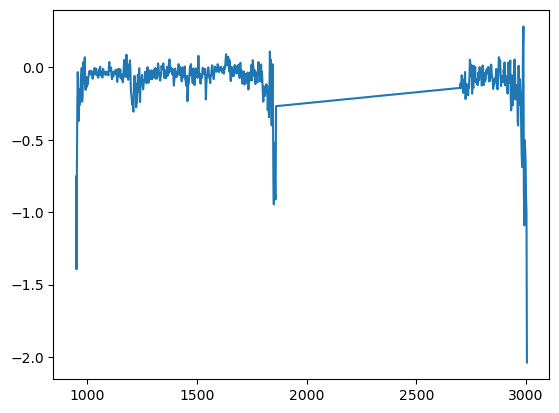

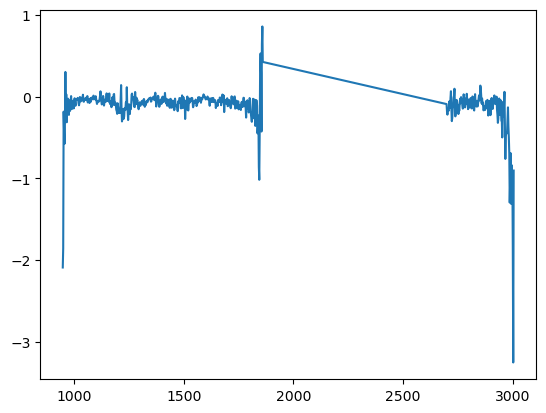

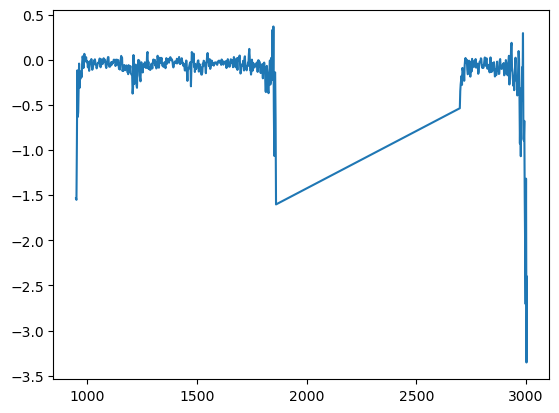

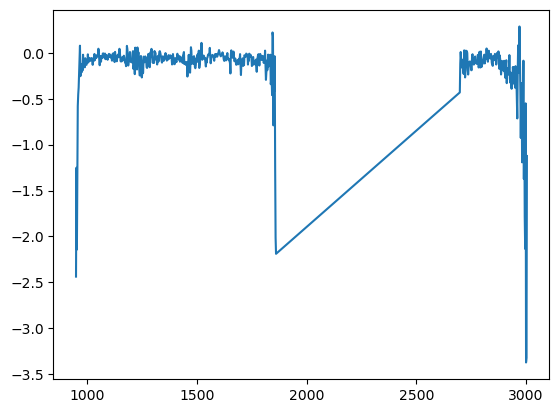

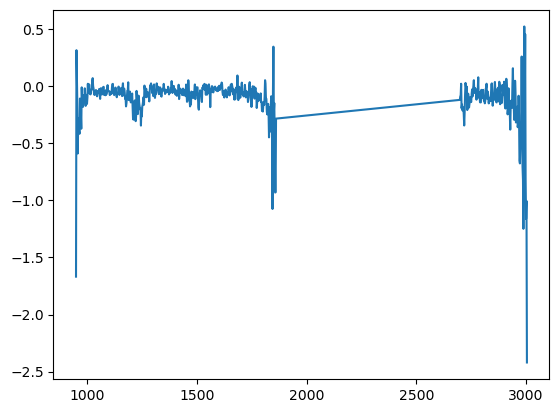

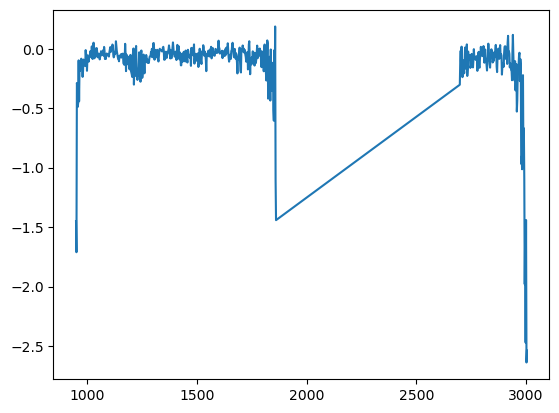

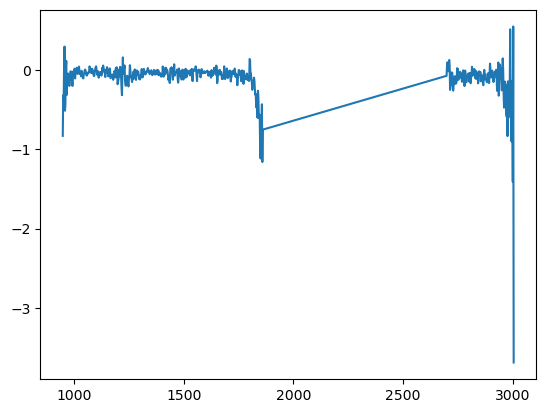

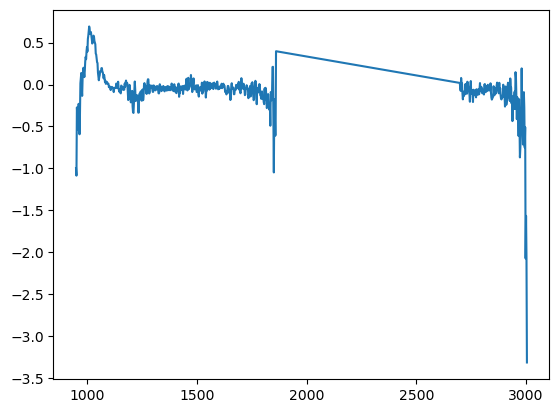

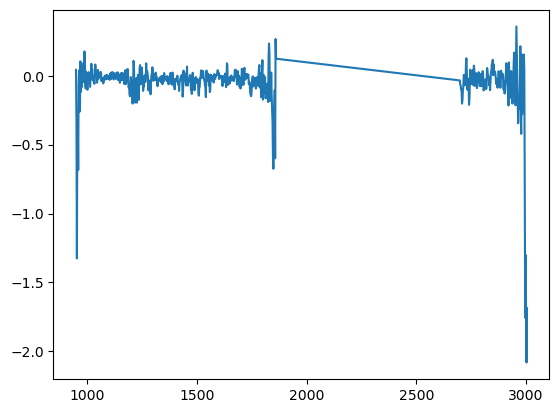

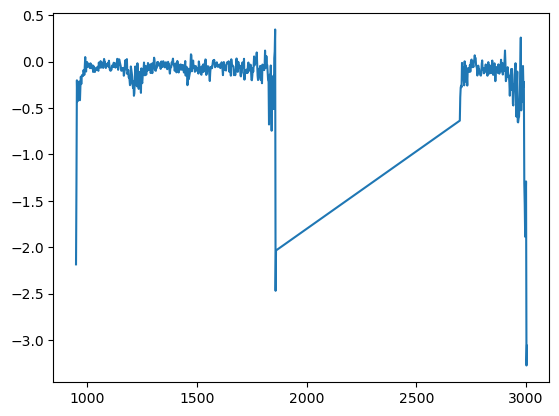

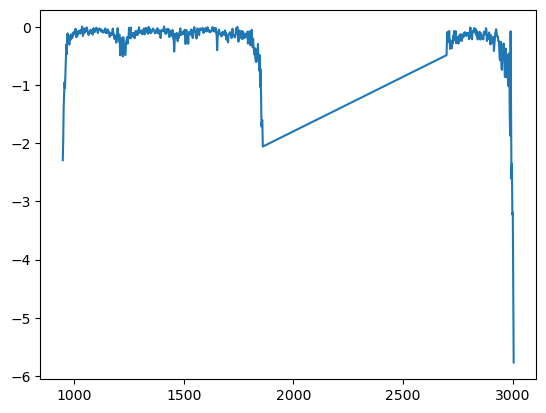

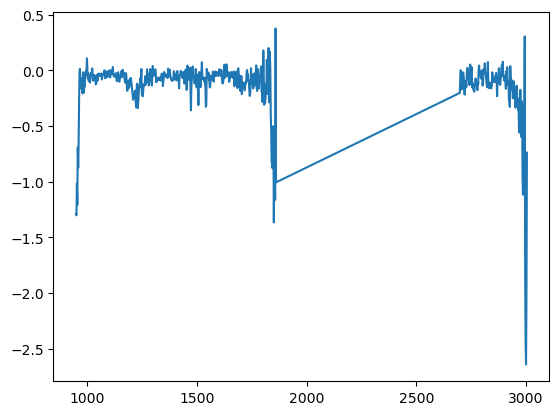

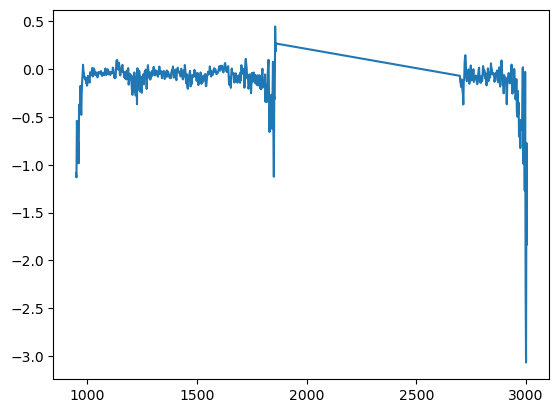

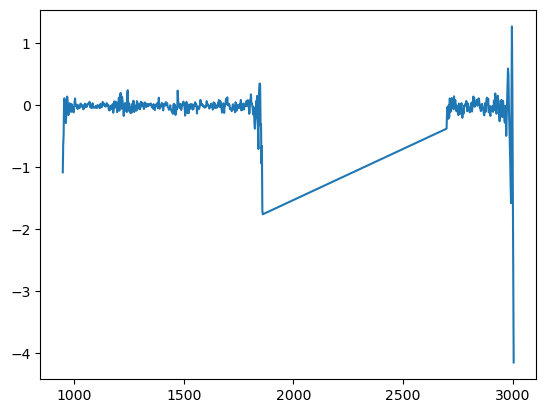

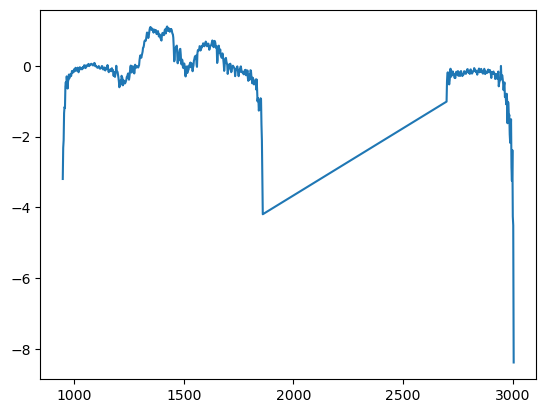

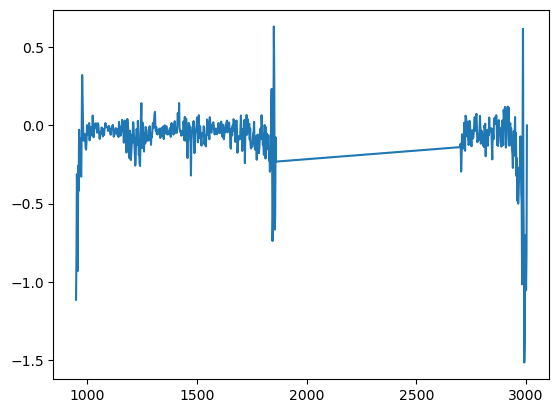

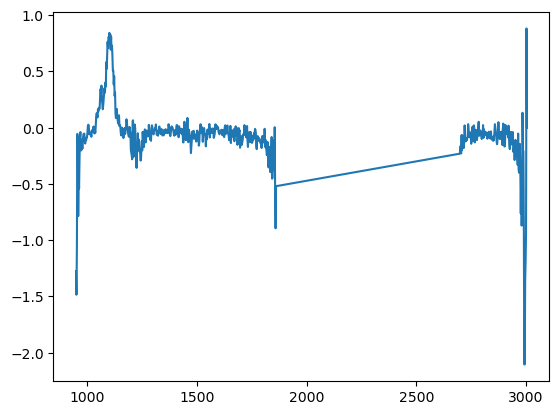

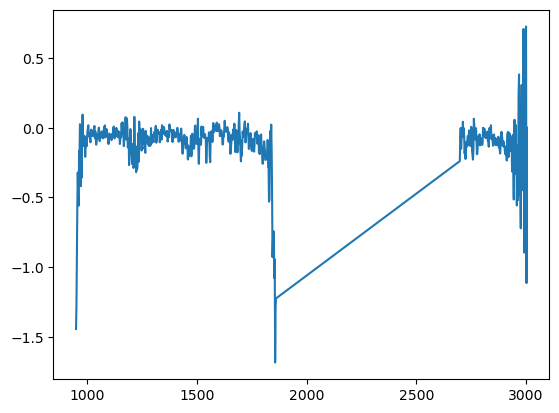

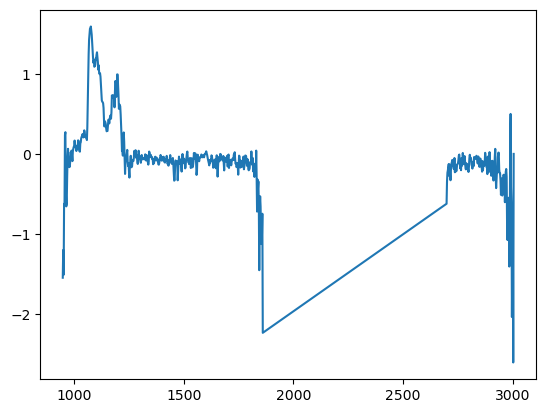

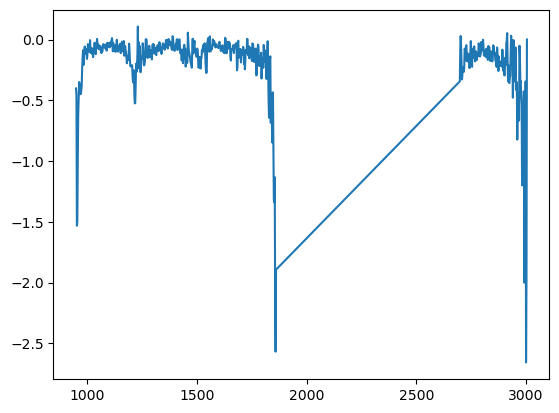

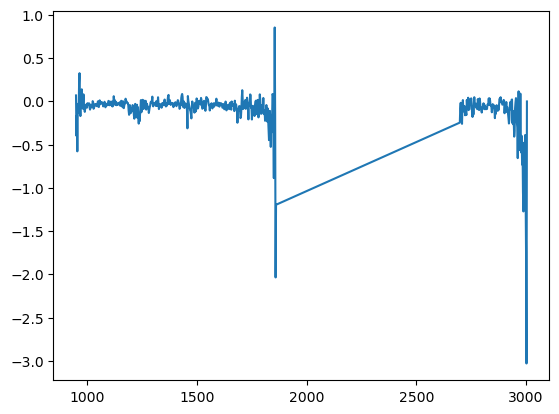

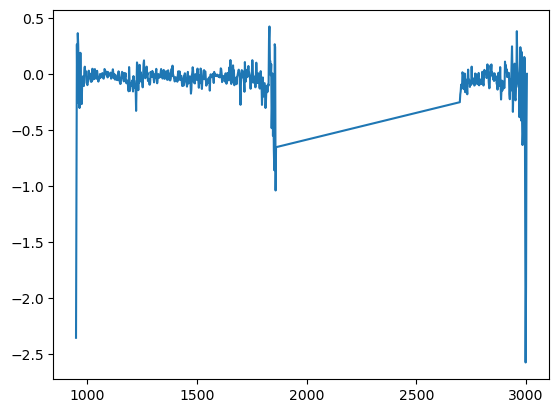

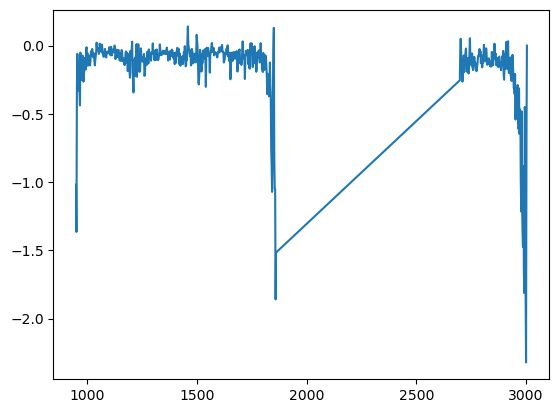

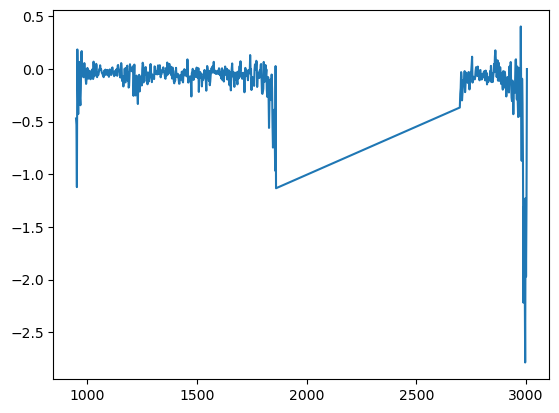

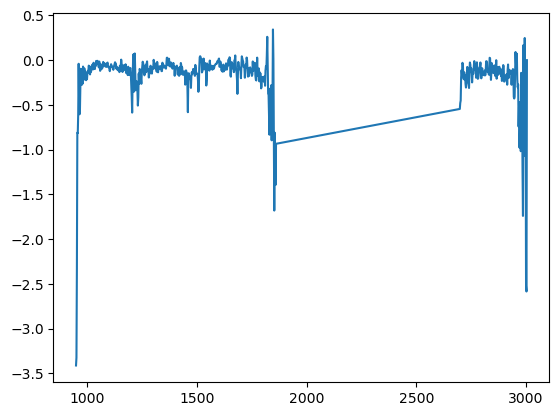

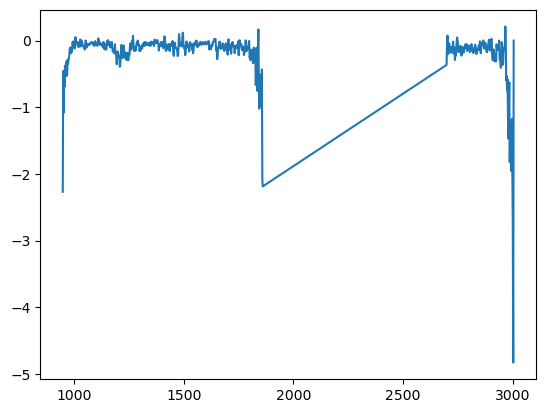

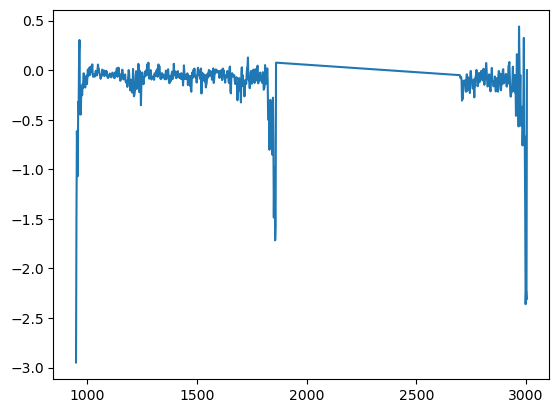

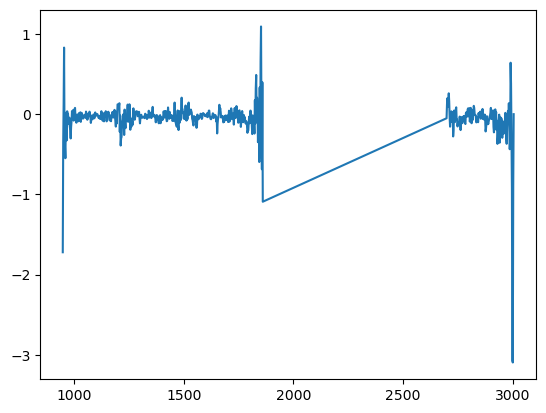

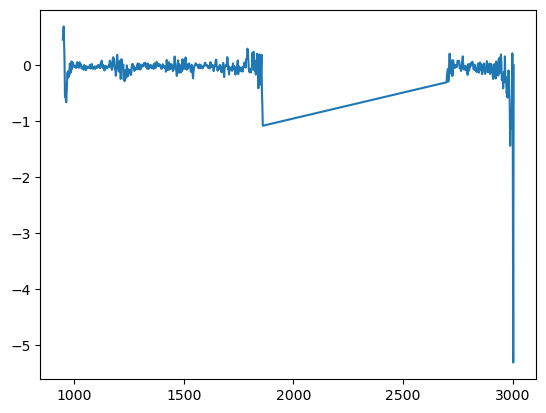

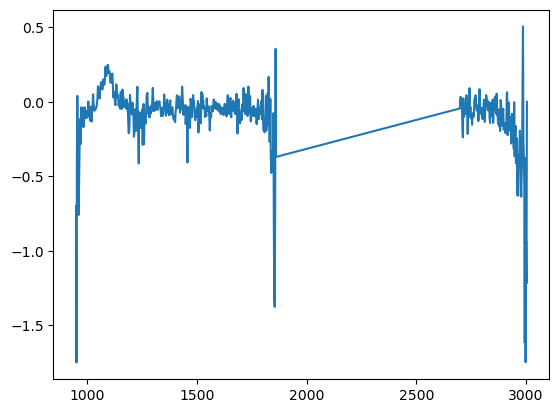

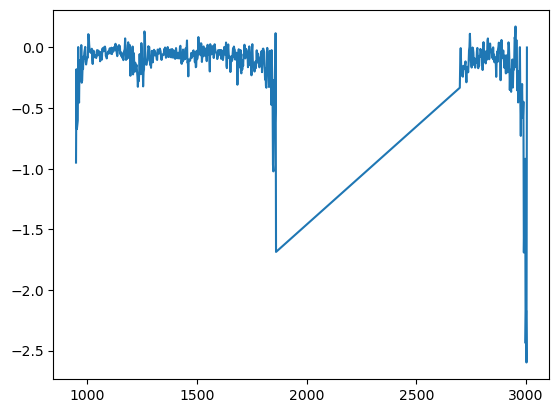

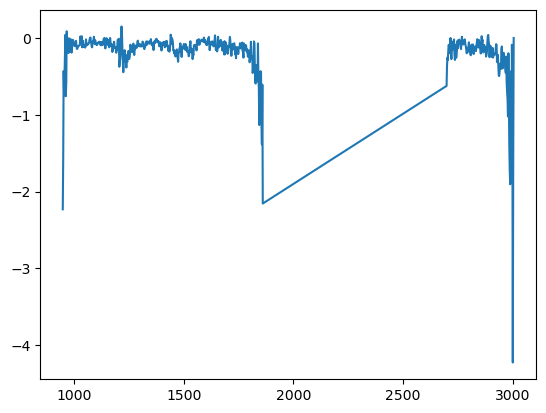

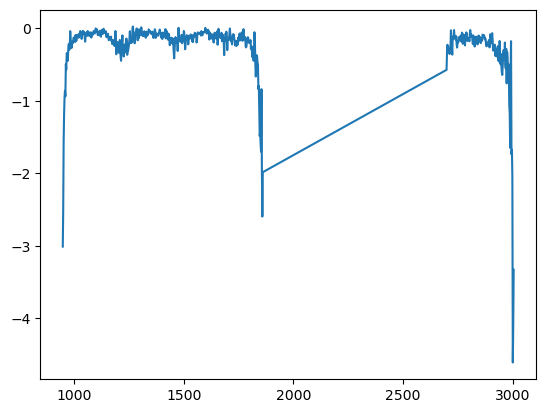

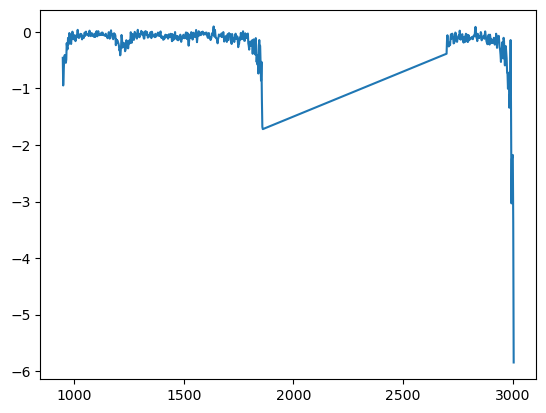

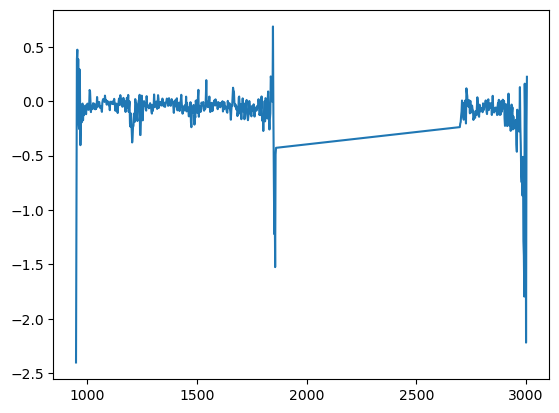

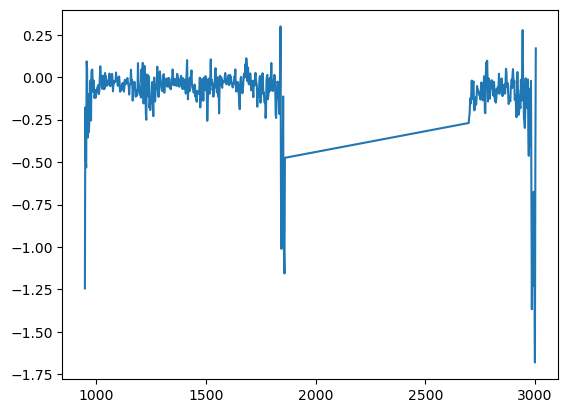

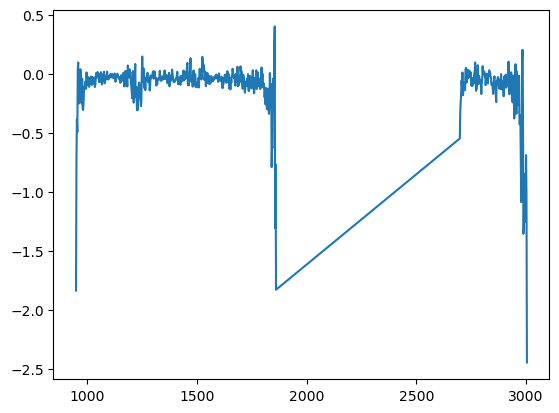

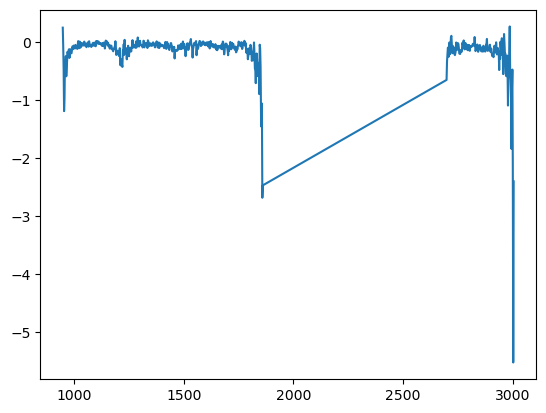

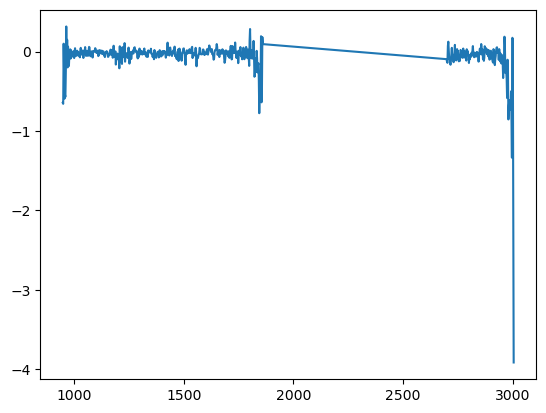

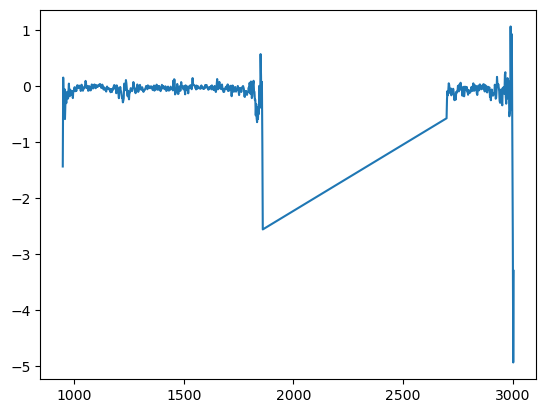

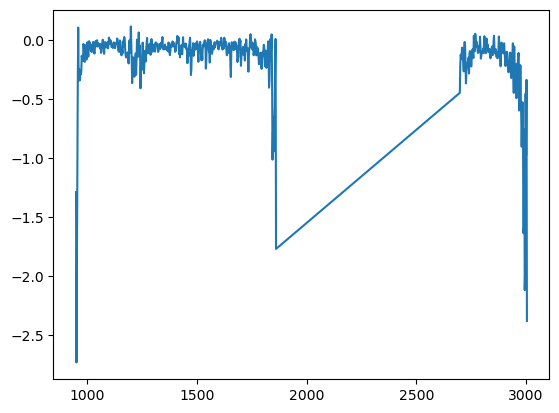

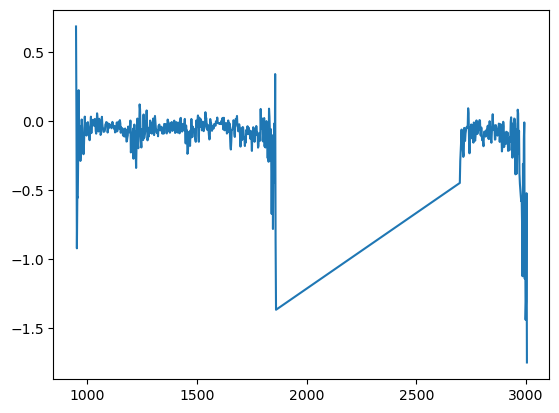

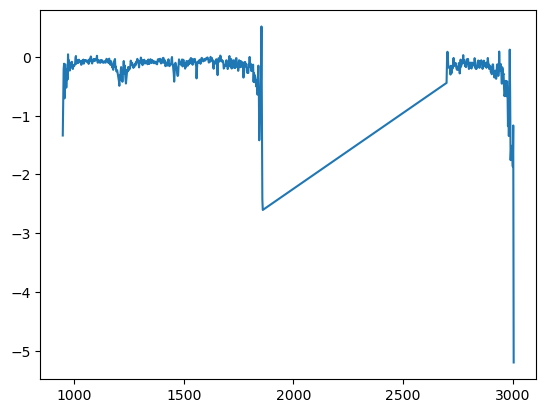

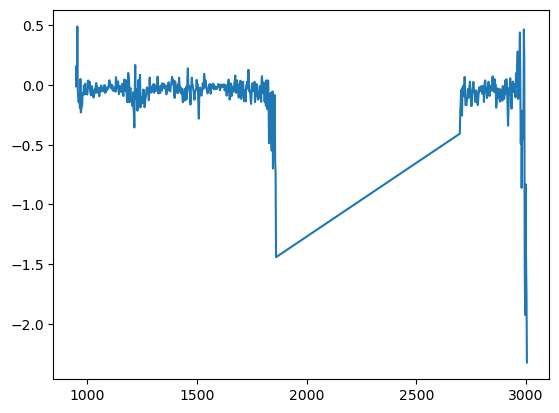

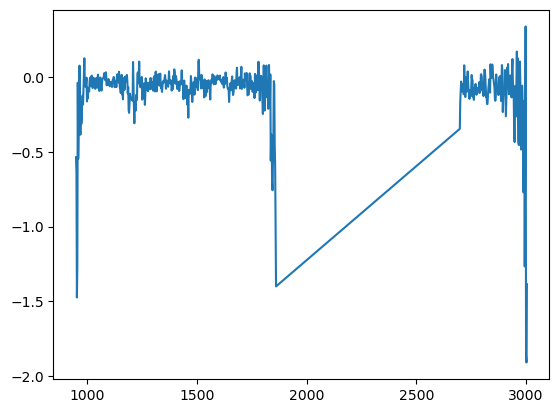

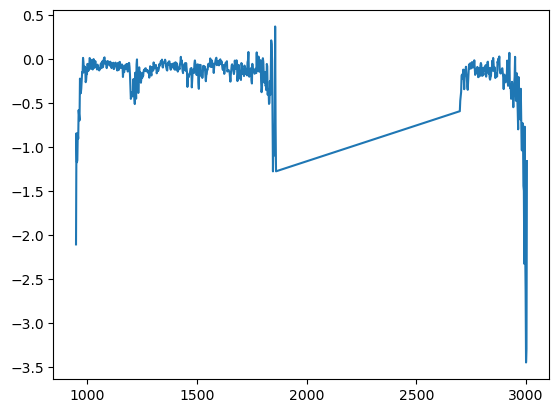

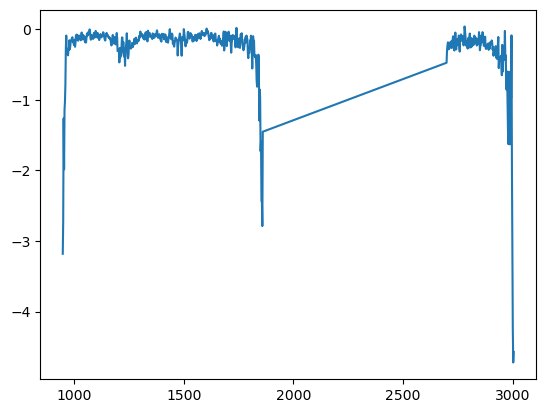

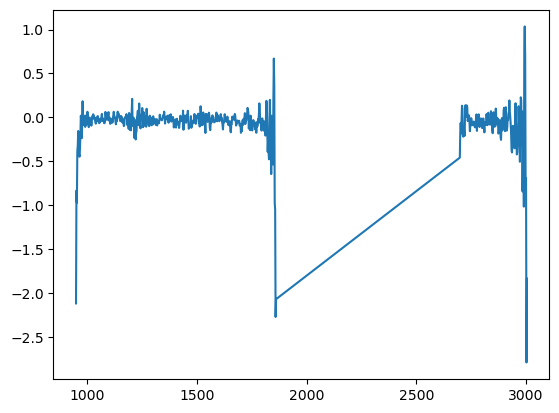

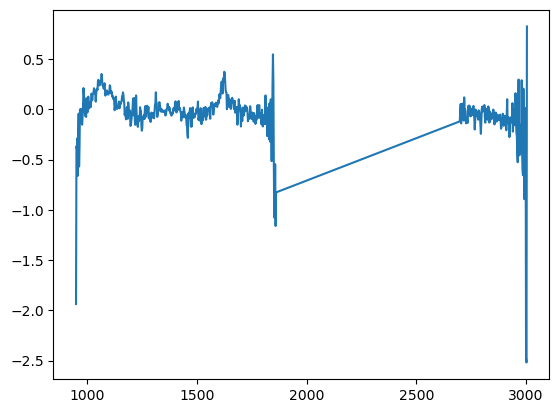

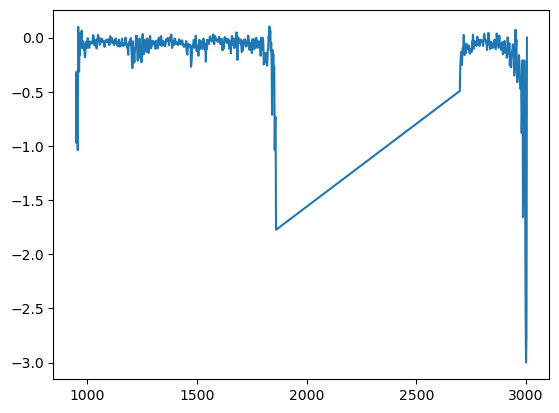

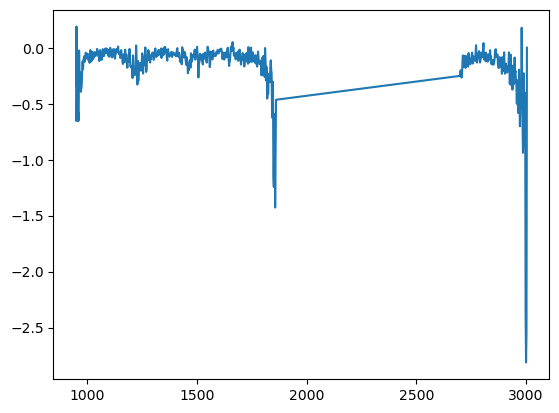

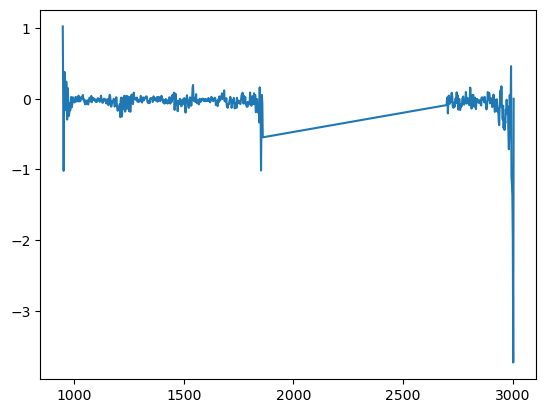

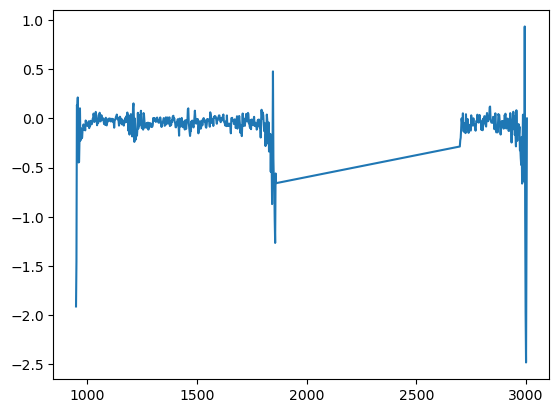

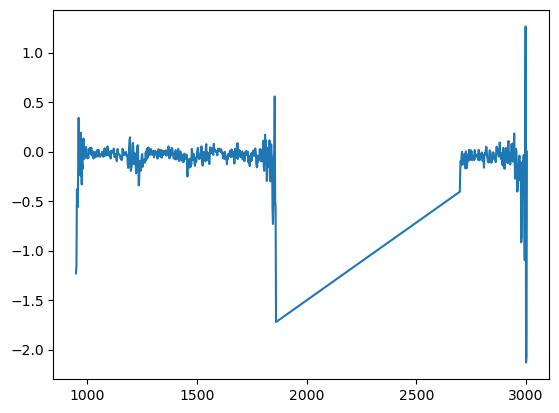

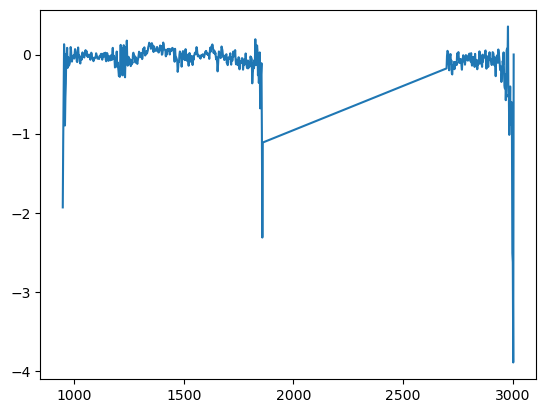

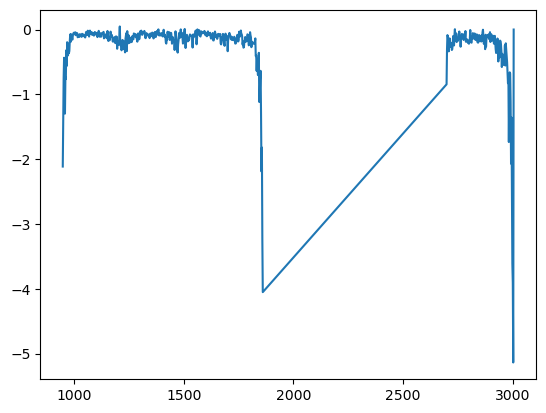

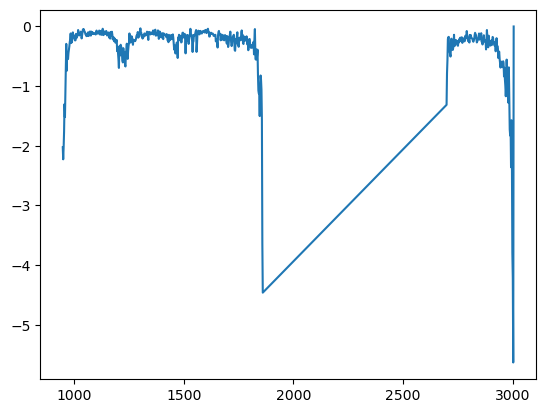

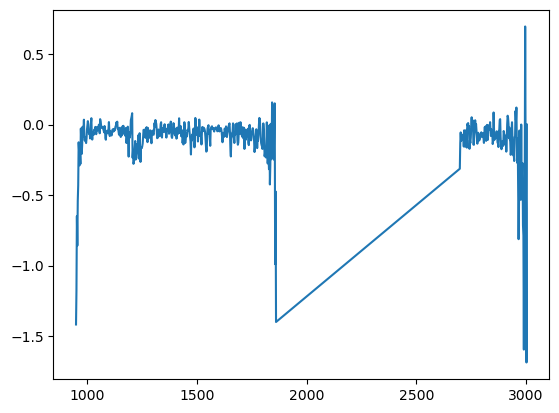

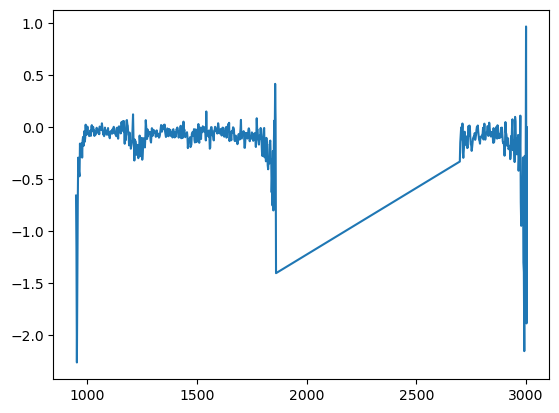

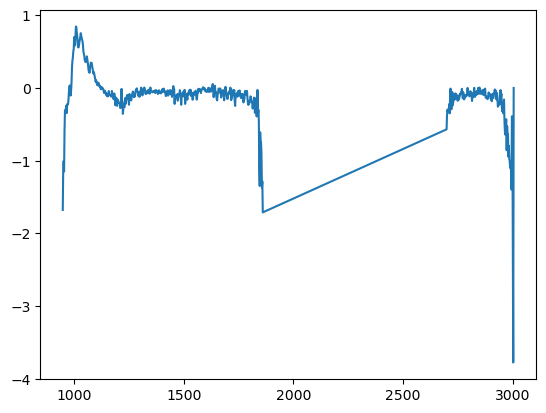

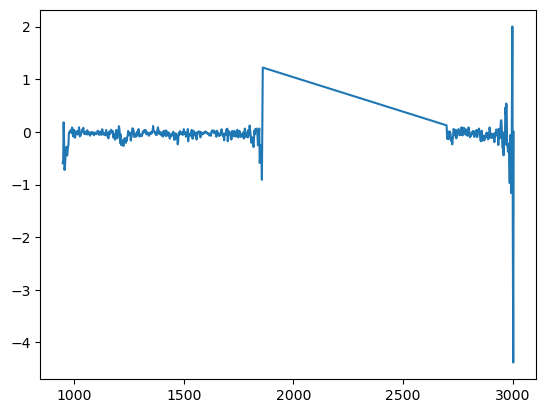

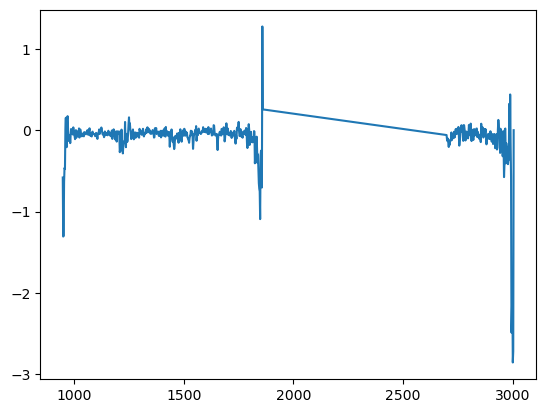

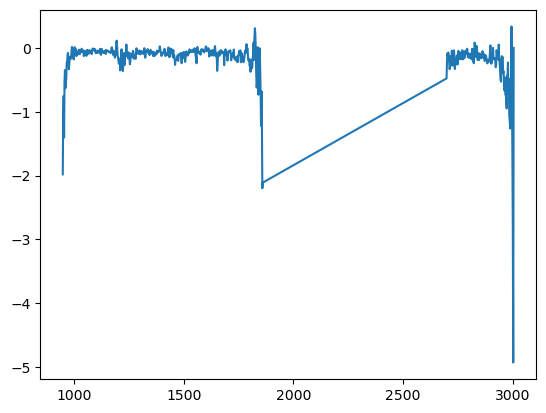

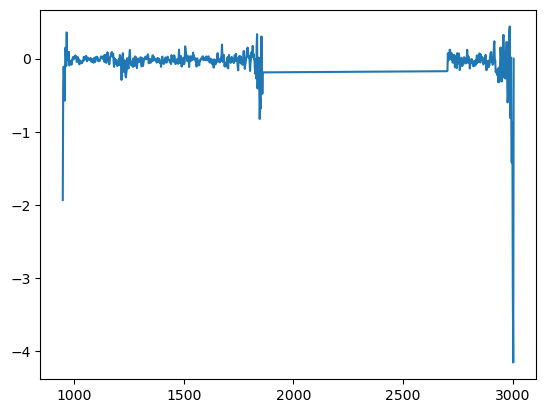

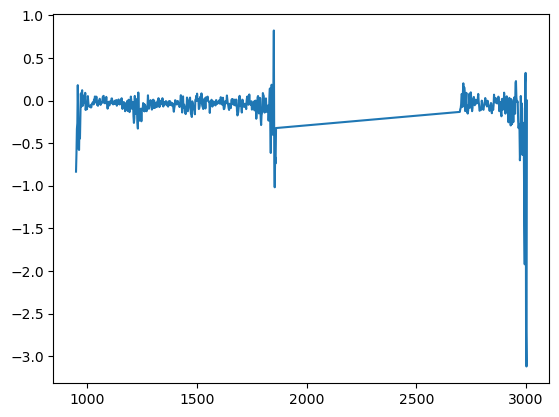

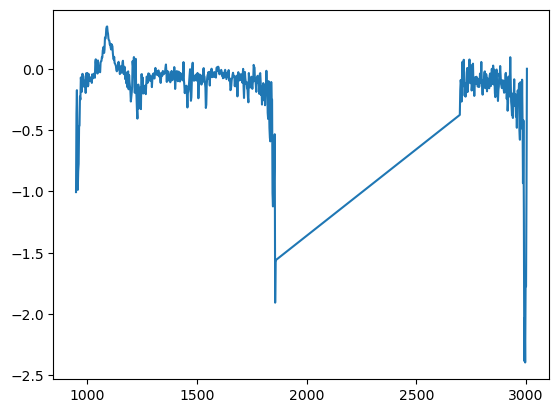

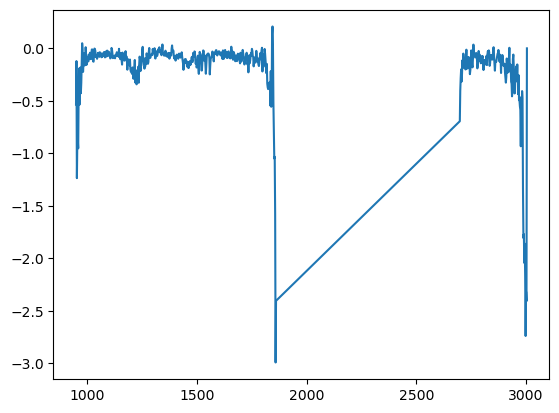

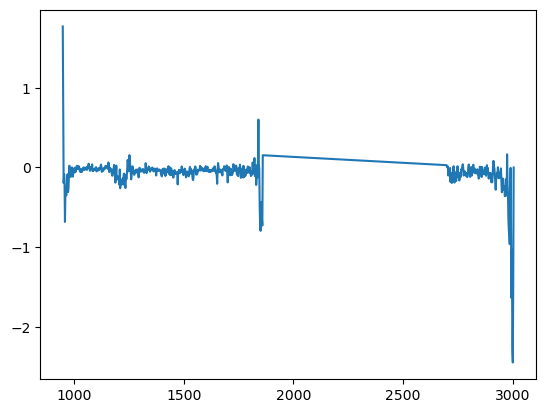

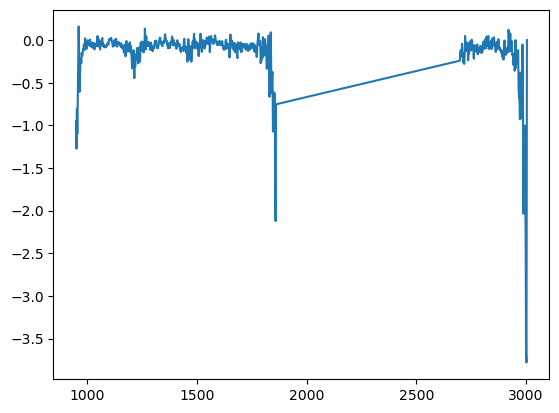

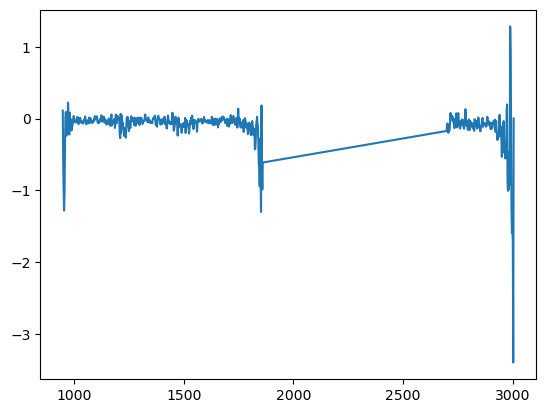

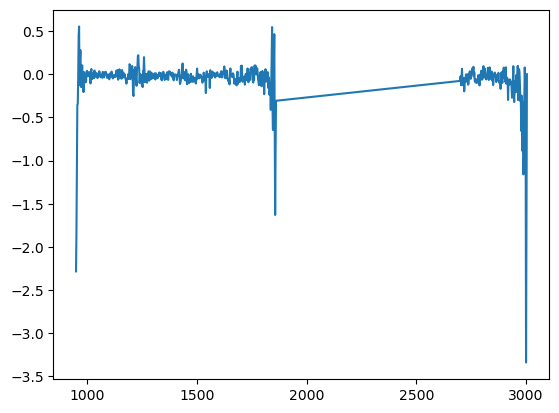

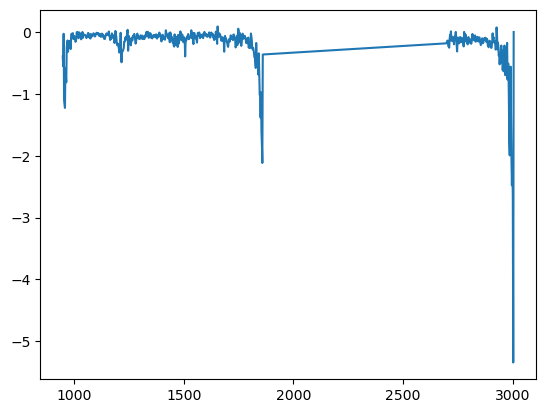

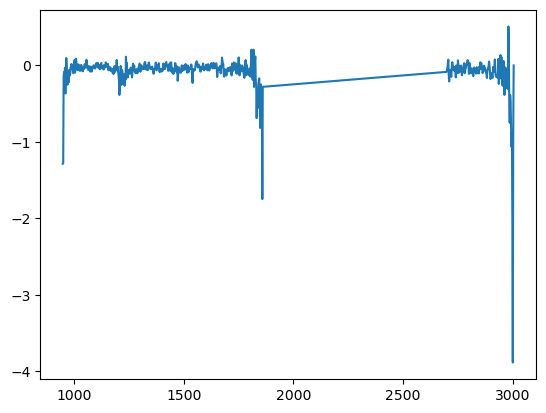

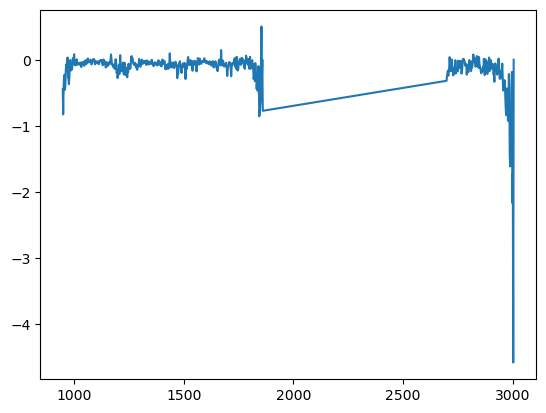

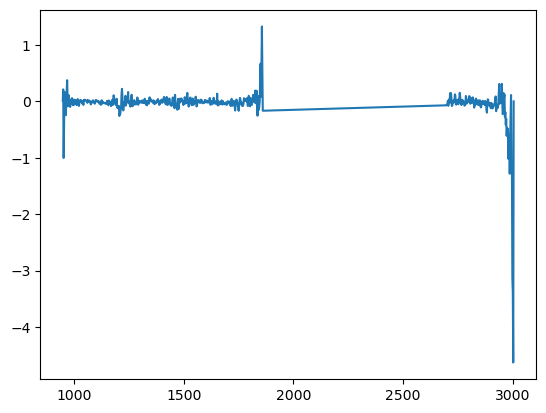

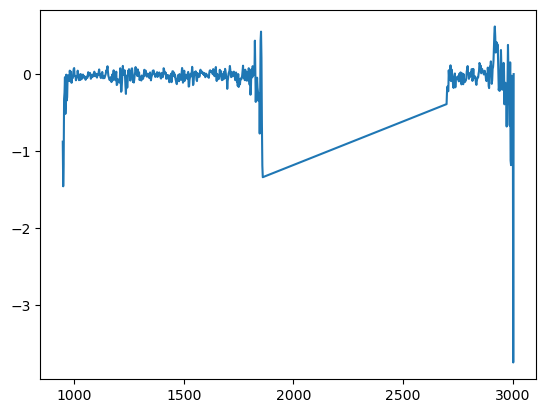

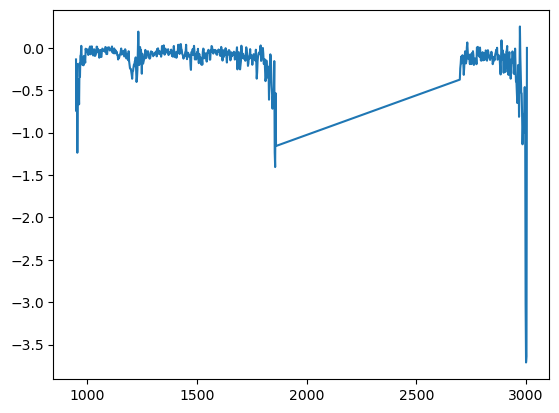

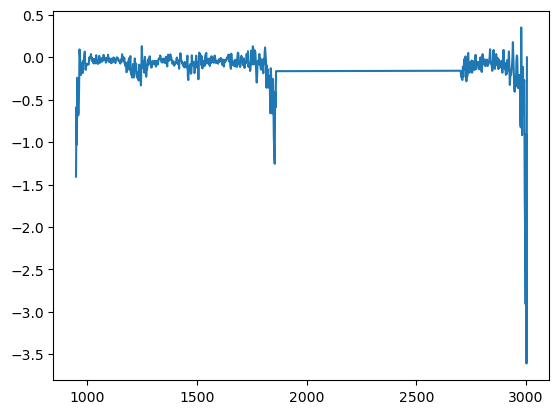

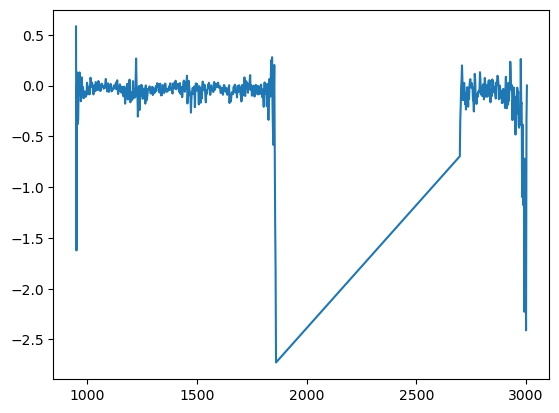

In [56]:
cluster = 1
n = spectra_df_bg.iloc[(pred == 0),:].iloc[(pred_2 == cluster),:].shape[0]    
for i in range(n):
    _ = plt.plot(spectra_df_bg.loc[(pred == 0),:].loc[(pred_2 == cluster),:].reset_index(drop=True).iloc[i,:].T)
    plt.show()

In [334]:
#for i in range(91):
#    plt.plot(spectra_df_bg.iloc[(pred == 0),:].iloc[(pred_2 == cluster),:].reset_index(drop=True).iloc[i,:])
#    plt.show()

In [57]:
np.array([x not in [1,2,3,4,5,7,9] for x in pred_2]).sum()

707

In [58]:
#spectra_bg_2 = spectra_bg_1[np.array([x not in [4,6,7,9] for x in pred_2])]
spectra_bg_2 = spectra_bg_1[np.array([x not in [1,2,3,4,5,7,9] for x in pred_2])]

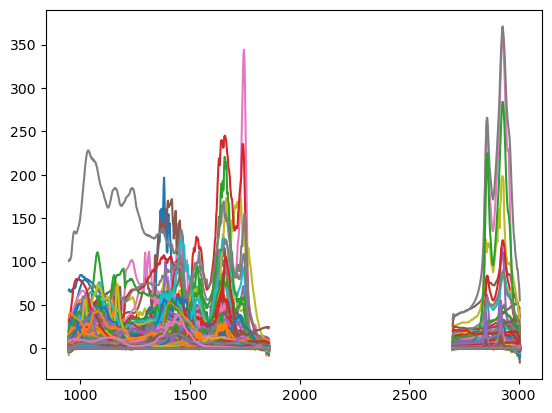

In [59]:
_ = plt.plot(spectra_df.query('id not in @spectra_bg_2').iloc[:,:-4].T)

In [62]:
spectra_df.query('id not in @spectra_bg_2').iloc[:,:-4].reset_index(drop=True)

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2986.0,2988.0,2990.0,2992.0,2994.0,2996.0,2998.0,3000.0,3002.0,3004.0
0,0.420147,0.201636,0.207516,0.366428,0.309315,0.374242,0.429199,0.555074,1.088998,1.455742,...,0.167070,0.225138,0.112434,-0.048182,0.268367,0.349250,0.324751,0.683293,0.758819,0.0
1,2.124952,1.581163,1.320649,0.218959,0.118063,0.393549,0.369571,0.311952,0.214783,0.329357,...,0.848304,-0.100549,-0.643169,0.167824,0.539628,0.074785,0.945301,0.115872,1.656565,0.0
2,-1.947177,-1.196911,-0.884133,-0.482069,-0.347420,-0.676806,-0.206153,0.182162,0.516461,0.564873,...,-1.087897,-1.731044,-0.812153,-0.876453,-1.002360,-2.432719,-1.504098,-3.150961,-1.170729,0.0
3,2.081793,2.523743,3.410621,4.196927,4.760760,4.768697,5.320252,5.180916,5.751516,5.896918,...,-1.027251,-1.142594,-1.391635,-1.721077,-2.085566,-0.510314,-0.682457,-1.814141,-2.051141,0.0
4,-0.170966,-0.017899,-0.171568,-0.054519,0.370269,0.323797,0.094333,-0.128107,0.031811,0.186388,...,0.280572,0.684245,0.594571,0.227177,-0.098507,0.611789,0.969728,-2.025087,-1.338049,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
743,-1.405876,-0.583997,-1.027777,-0.240136,-0.504393,-0.683092,-0.653036,-0.363525,0.093857,-0.003562,...,-0.112188,-0.559133,-0.291866,-0.269736,-1.629161,-2.123788,-2.908056,-0.901653,-3.607500,0.0
744,0.535237,1.168425,0.605069,0.501292,0.044438,0.268000,0.391625,-0.004522,-0.000675,-0.059564,...,0.790682,-0.328912,0.645066,1.126433,-0.164432,0.072319,-0.083602,0.423088,2.268882,0.0
745,-0.055207,0.284365,0.170684,0.525568,0.680325,0.166145,0.043483,-0.229362,-0.193651,0.075511,...,0.545472,0.178178,0.137289,0.282144,0.835744,0.298983,-0.448608,0.947676,0.344176,0.0
746,8.834106,9.517404,9.789485,9.474477,9.907725,10.047929,9.970377,10.140451,10.239701,10.326295,...,-0.171074,-0.340743,-0.143738,0.245700,0.354390,0.585832,0.734295,1.742851,0.431219,0.0


In [68]:
#spectra_df.query('id not in @spectra_bg_2').reset_index(drop=True).to_csv('OPTIR/Blank/data_all.csv')#.iloc[:,:-2]
#spectra_df.query('id in @spectra_bg_2').reset_index(drop=True).to_csv('OPTIR/Blank/data_background.csv')#.iloc[:,:-2]
spectra_df.to_csv('OPTIR/Blank/data_all_raman.csv')

In [68]:
list(spectra_bg_2)[0]

'ICB_Run2_1'

In [317]:
[x for x in spectra_df['id']]

['ICB_Run2_1',
 'ICB_Run2_2',
 'ICB_Run2_3',
 'ICB_Run2_4',
 'ICB_Run2_5',
 'ICB_Run2_6',
 'ICB_Run2_7',
 'ICB_Run2_8',
 'ICB_Run2_9',
 'ICB_Run2_10',
 'ICB_Run2_11',
 'ICB_Run2_12',
 'ICB_Run2_13',
 'ICB_Run2_14',
 'ICB_Run2_15',
 'ICB_Run2_16',
 'ICB_Run2_17',
 'ICB_Run2_18',
 'ICB_Run2_19',
 'ICB_Run2_20',
 'ICB_Run2_21',
 'ICB_Run2_22',
 'ICB_Run2_23',
 'ICB_Run2_24',
 'ICB_Run2_25',
 'ICB_Run2_26',
 'ICB_Run2_27',
 'ICB_Run2_28',
 'ICB_Run2_29',
 'ICB_Run2_30',
 'ICB_Run2_31',
 'ICB_Run2_32',
 'ICB_Run2_33',
 'ICB_Run2_34',
 'ICB_Run2_35',
 'ICB_Run2_36',
 'ICB_Run2_37',
 'ICB_Run2_38',
 'ICB_Run2_39',
 'ICB_Run2_40',
 'ICB_Run2_41',
 'ICB_Run2_42',
 'ICB_Run2_43',
 'ICB_Run2_44',
 'ICB_Run2_45',
 'ICB_Run2_46',
 'ICB_Run2_47',
 'ICB_Run2_48',
 'ICB_Run2_49',
 'ICB_Run2_50',
 'ICB_Run2_51',
 'ICB_Run2_52',
 'ICB_Run2_53',
 'ICB_Run2_54',
 'ICB_Run2_55',
 'ICB_Run2_56',
 'ICB_Run2_57',
 'ICB_Run2_58',
 'ICB_Run2_59',
 'ICB_Run2_60',
 'ICB_Run2_61',
 'ICB_Run2_62',
 'ICB_Run2_63',
 

In [179]:
spectra_df['background'] = ['background' if x in list(spectra_bg_2) else 'no-background'for x in spectra_df['id']]

In [183]:
spectra_df_summary = spectra_df.groupby(['run_file_name','background']).count().reset_index()
spectra_df_summary
spectra_df_summary['school'] = [x[10:20] for x in spectra_df_summary['run_file_name']]
spectra_df_summary = spectra_df_summary.groupby(['school','background']).sum('948.0').iloc[:,:1].reset_index()
spectra_df_summary.columns = ['school', 'background', '# spectra']
spectra_df_summary['school'] = [
    'Daycroft',
    'Daycroft',
    'FHS',
    'FHS',
    'IAO',
    'IAO',
    'ICB',
    'ICB'
]
spectra_df_summary.set_index(['school', 'background'])

# spectra
school   background              
Daycroft background           211
         no-background        124
FHS      background           213
         no-background        181
IAO      background           254
         no-background         94
ICB      background           224
         no-background        142

In [187]:
spectra_df_summary.groupby('background').sum()

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97043/3256403558.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  spectra_df_summary.groupby('background').sum()


,# spectra
background,
background,902
no-background,541
